In [2]:

# Import the libraries needed to work with data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read the uploaded CSV file
df = pd.read_csv("/content/Nassau Candy Distributor.csv")

# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the first five records
display(df.head())

# Check the data types of all columns
print("\nData types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check exact duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (10194, 18)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90



Data types:
Row ID              int64
Order ID           object
Order Date         object
Ship Date          object
Ship Mode          object
Customer ID         int64
Country/Region     object
City               object
State/Province     object
Postal Code        object
Division           object
Region             object
Product ID         object
Product Name       object
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

Duplicate rows: 0


In [3]:

# Convert date columns to real date values
df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], dayfirst=True, errors="coerce"
)

# Calculate shipping lead time in days
df["Lead Time Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Check the date ranges
print("Order date range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

print("\nShip date range:")
print(df["Ship Date"].min(), "to", df["Ship Date"].max())

# Summarize shipping lead time
print("\nLead time statistics:")
display(df["Lead Time Days"].describe())

# Count impossible date sequences
print(
    "\nShip dates before order dates:",
    (df["Lead Time Days"] < 0).sum()
)


Order date range:
2024-01-02 00:00:00 to 2025-12-31 00:00:00

Ship date range:
2026-06-30 00:00:00 to 2030-06-28 00:00:00

Lead time statistics:


,Lead Time Days
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000



Ship dates before order dates: 0


In [4]:

# Summary statistics for numerical columns
display(
    df[["Sales", "Units", "Gross Profit", "Cost"]].describe()
)

# Check whether sales equal gross profit plus cost
difference = (
    df["Sales"] - df["Gross Profit"] - df["Cost"]
)

print(
    "Rows where Sales != Gross Profit + Cost:",
    (~np.isclose(difference, 0)).sum()
)

# Check for negative or zero business values
for column in ["Sales", "Units", "Gross Profit", "Cost"]:
    print(
        column,
        "| Negative values:", (df[column] < 0).sum(),
        "| Zero values:", (df[column] == 0).sum()
    )


,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,13.908537,3.791838,9.166451,4.742087
std,11.341020,2.228317,6.643740,5.061647
min,1.250000,1.000000,0.250000,0.600000
25%,7.200000,2.000000,4.900000,2.400000
50%,10.800000,3.000000,7.470000,3.600000
75%,18.000000,5.000000,12.250000,5.700000
max,260.000000,14.000000,130.000000,130.000000


Rows where Sales != Gross Profit + Cost: 0
Sales | Negative values: 0 | Zero values: 0
Units | Negative values: 0 | Zero values: 0
Gross Profit | Negative values: 0 | Zero values: 0
Cost | Negative values: 0 | Zero values: 0


Division
Chocolate    131692.90
Other          9663.25
Sugar           427.48
Name: Sales, dtype: float64


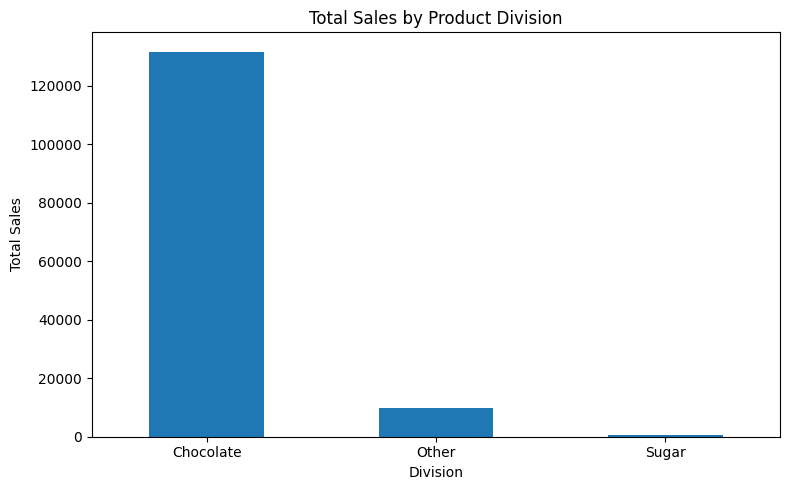

In [5]:

# Calculate total sales for each division
division_sales = (
    df.groupby("Division")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(division_sales)

# Create a bar chart
division_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Sales by Product Division")
plt.xlabel("Division")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Total_Sales,Total_Profit,Total_Units,Order_Count
Region,,,,
Pacific,46301.53,30485.94,12466,2744
Atlantic,41197.24,26973.70,11159,2476
Interior,32037.60,21282.49,8820,1979
Gulf,22247.26,14700.67,6209,1350


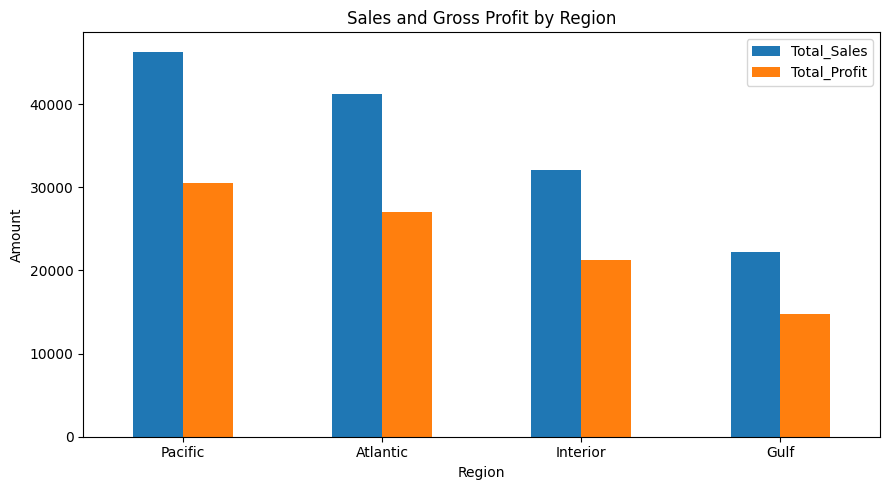

In [6]:

region_summary = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum"),
        Order_Count=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(region_summary)

region_summary[["Total_Sales", "Total_Profit"]].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Sales and Gross Profit by Region")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [7]:

shipping_summary = (
    df.groupby("Ship Mode")
    .agg(
        Orders=("Order ID", "nunique"),
        Sales=("Sales", "sum"),
        Gross_Profit=("Gross Profit", "sum"),
        Units=("Units", "sum")
    )
)

display(shipping_summary)


,Orders,Sales,Gross_Profit,Units
Ship Mode,,,,
First Class,1312,21319.39,14011.09,5724
Same Day,442,7113.67,4700.73,1975
Second Class,1653,27860.22,18306.52,7546
Standard Class,5142,85490.35,56424.46,23409


In [8]:

# STEP 1: Check unique products
print("Number of unique products:",
      df["Product ID"].nunique())

print("\nProducts per division:")
display(
    df.groupby("Division")["Product ID"]
      .nunique()
)

# STEP 2: Check shipping modes
print("\nAvailable shipping modes:")
print(df["Ship Mode"].unique())

# STEP 3: Check regions
print("\nAvailable regions:")
print(df["Region"].unique())

# STEP 4: Check whether product IDs
# have more than one product name
product_name_counts = (
    df.groupby("Product ID")["Product Name"]
      .nunique()
)

print(
    "\nProduct IDs with multiple names:",
    (product_name_counts > 1).sum()
)

# STEP 5: Inspect the date pattern
print("\nFirst 10 order and ship dates:")
display(
    df[["Order ID", "Order Date", "Ship Date"]].head(10)
)


Number of unique products: 15

Products per division:


,Product ID
Division,
Chocolate,5
Other,3
Sugar,7



Available shipping modes:
['Standard Class' 'First Class' 'Second Class' 'Same Day']

Available regions:
['Interior' 'Atlantic' 'Gulf' 'Pacific']

Product IDs with multiple names: 0

First 10 order and ship dates:


,Order ID,Order Date,Ship Date
0,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30
1,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01
2,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01
3,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01
4,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05
5,US-2021-167199-CHO-SCR-58000,2024-01-06,2026-07-03
6,US-2021-167199-CHO-TRI-54000,2024-01-06,2026-07-03
7,US-2021-106054-CHO-MIL-31000,2024-01-06,2026-06-30
8,US-2021-167199-CHO-NUT-13000,2024-01-06,2026-07-03
9,US-2021-167199-CHO-MIL-31000,2024-01-06,2026-07-03


In [9]:

# 1. Check whether factory-related columns exist
print("Factory-related columns:")
print([
    col for col in df.columns
    if "factory" in col.lower()
])

# 2. Check date differences
df["Lead Time Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("\nLead time summary:")
display(df["Lead Time Days"].describe())

# 3. Check whether shipping dates are after order dates
print(
    "\nShip date before order date:",
    (df["Ship Date"] < df["Order Date"]).sum()
)

# 4. Check product-to-division consistency
division_counts = (
    df.groupby("Product ID")["Division"]
      .nunique()
)

print(
    "\nProduct IDs assigned to multiple divisions:",
    (division_counts > 1).sum()
)

# 5. Check numerical data for invalid values
numeric_columns = [
    "Sales", "Units", "Gross Profit", "Cost"
]

display(df[numeric_columns].describe())


Factory-related columns:
[]

Lead time summary:


,Lead Time Days
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000



Ship date before order date: 0

Product IDs assigned to multiple divisions: 0


,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,13.908537,3.791838,9.166451,4.742087
std,11.341020,2.228317,6.643740,5.061647
min,1.250000,1.000000,0.250000,0.600000
25%,7.200000,2.000000,4.900000,2.400000
50%,10.800000,3.000000,7.470000,3.600000
75%,18.000000,5.000000,12.250000,5.700000
max,260.000000,14.000000,130.000000,130.000000


In [10]:

# STEP 1: Create the product-to-factory mapping

import re

factory_mapping = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar - Scrumdiddlyumptious": "Lot's O' Nuts",
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",
    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",
    "Everlasting Gobstopper": "Secret Factory",
    "Hair Toffee": "The Other Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",
    "Kazookles": "The Other Factory"
}

# Normalize names to avoid mismatches caused by
# capitalization, spaces, and punctuation.
def normalize_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

normalized_mapping = {
    normalize_name(product): factory
    for product, factory in factory_mapping.items()
}

# Add the current factory to each matching product
df["Factory"] = df["Product Name"].map(
    lambda name: normalized_mapping.get(
        normalize_name(name)
    )
)

# Check whether the mapping worked
print("Total dataset rows:", len(df))
print("Rows matched to a factory:", df["Factory"].notna().sum())
print("Rows without a factory:", df["Factory"].isna().sum())

print("\nFactory distribution:")
display(df["Factory"].value_counts(dropna=False))

print("\nProducts without a factory mapping:")
display(
    df.loc[df["Factory"].isna(), "Product Name"]
      .drop_duplicates()
      .sort_values()
)


Total dataset rows: 10194
Rows matched to a factory: 10194
Rows without a factory: 0

Factory distribution:


,count
Factory,
Lot's O' Nuts,5692
Wicked Choccy's,4152
Secret Factory,217
The Other Factory,100
Sugar Shack,33



Products without a factory mapping:


,Product Name


In [11]:

# STEP 2A: Create a table of factory locations

factory_locations = {
    "Lot's O' Nuts": (32.881893, -111.768036),
    "Wicked Choccy's": (32.076176, -81.088371),
    "Sugar Shack": (48.11914, -96.18115),
    "Secret Factory": (41.446333, -90.565487),
    "The Other Factory": (35.1175, -89.971107)
}

# Add latitude and longitude to every order
df["Factory Latitude"] = df["Factory"].map(
    lambda factory: factory_locations[factory][0]
)

df["Factory Longitude"] = df["Factory"].map(
    lambda factory: factory_locations[factory][1]
)

# Display the factory location table
factory_df = pd.DataFrame([
    {
        "Factory": name,
        "Latitude": coordinates[0],
        "Longitude": coordinates[1]
    }
    for name, coordinates in factory_locations.items()
])

display(factory_df)

# Check that every row has coordinates
print(
    "\nRows missing factory coordinates:",
    df[["Factory Latitude", "Factory Longitude"]]
      .isnull().any(axis=1).sum()
)


,Factory,Latitude,Longitude
0,Lot's O' Nuts,32.881893,-111.768036
1,Wicked Choccy's,32.076176,-81.088371
2,Sugar Shack,48.119140,-96.181150
3,Secret Factory,41.446333,-90.565487
4,The Other Factory,35.117500,-89.971107



Rows missing factory coordinates: 0


In [12]:

# STEP 2B: Data-quality checks

print("Dataset shape:", df.shape)

# Check missing values
print("\nMissing values by column:")
display(df.isnull().sum())

# Check invalid numerical values
numeric_columns = [
    "Sales", "Units", "Gross Profit", "Cost"
]

print("\nNegative numerical values:")
for column in numeric_columns:
    print(column, ":", (df[column] < 0).sum())

# Check date order
df["Lead Time Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("\nLead-time summary:")
display(df["Lead Time Days"].describe())

print(
    "\nShip dates before order dates:",
    (df["Lead Time Days"] < 0).sum()
)

# Check whether product names match multiple divisions
division_counts = (
    df.groupby("Product Name")["Division"].nunique()
)

print(
    "\nProducts linked to multiple divisions:",
    (division_counts > 1).sum()
)

# Check duplicate order IDs
print(
    "\nUnique orders:",
    df["Order ID"].nunique()
)


Dataset shape: (10194, 22)

Missing values by column:


,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
City,0
State/Province,0
Postal Code,0



Negative numerical values:
Sales : 0
Units : 0
Gross Profit : 0
Cost : 0

Lead-time summary:


,Lead Time Days
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000



Ship dates before order dates: 0

Products linked to multiple divisions: 0

Unique orders: 8549


In [13]:

# STEP 3: Investigate suspicious shipping dates

# Ensure both date columns use the correct date format
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

# Display the earliest and latest dates
print("Order date range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

print("\nShip date range:")
print(df["Ship Date"].min(), "to", df["Ship Date"].max())

# Count orders by order year
print("\nOrders by order year:")
display(df["Order Date"].dt.year.value_counts().sort_index())

# Count shipments by shipping year
print("\nShipments by shipping year:")
display(df["Ship Date"].dt.year.value_counts().sort_index())

# Compare order year and shipping year
print("\nOrder year vs shipping year:")
display(pd.crosstab(
    df["Order Date"].dt.year,
    df["Ship Date"].dt.year
))

# Inspect the shortest and longest lead times
print("\n10 shortest lead times:")
display(
    df.nsmallest(10, "Lead Time Days")[
        ["Order ID", "Order Date", "Ship Date", "Ship Mode",
         "Product Name", "Lead Time Days"]
    ]
)

print("\n10 longest lead times:")
display(
    df.nlargest(10, "Lead Time Days")[
        ["Order ID", "Order Date", "Ship Date", "Ship Mode",
         "Product Name", "Lead Time Days"]
    ]
)

# Count dates that could not be parsed
print("\nInvalid order dates:", df["Order Date"].isna().sum())
print("Invalid ship dates:", df["Ship Date"].isna().sum())


Order date range:
2024-01-02 00:00:00 to 2025-12-31 00:00:00

Ship date range:
2026-06-30 00:00:00 to 2030-06-28 00:00:00

Orders by order year:


,count
Order Date,
2024,4181
2025,6013



Shipments by shipping year:


,count
Ship Date,
2026,711
2027,2089
2028,2367
2029,2899
2030,2128



Order year vs shipping year:


...


10 shortest lead times:


,Order ID,Order Date,Ship Date,Ship Mode,Product Name,Lead Time Days
154,US-2021-116239-CHO-FUD-51000,2024-03-04,2026-08-25,Same Day,Wonka Bar - Fudge Mallows,904
203,US-2021-158442-CHO-MIL-31000,2024-03-17,2026-09-07,Same Day,Wonka Bar - Milk Chocolate,904
211,US-2021-158442-CHO-FUD-51000,2024-03-17,2026-09-07,Same Day,Wonka Bar - Fudge Mallows,904
212,US-2021-158442-CHO-TRI-54000,2024-03-17,2026-09-07,Same Day,Wonka Bar - Triple Dazzle Caramel,904
247,US-2021-129609-CHO-TRI-54000,2024-03-22,2026-09-12,Same Day,Wonka Bar - Triple Dazzle Caramel,904
280,US-2021-130428-CHO-FUD-51000,2024-03-31,2026-09-21,Same Day,Wonka Bar - Fudge Mallows,904
282,US-2021-130428-CHO-TRI-54000,2024-03-31,2026-09-21,Same Day,Wonka Bar - Triple Dazzle Caramel,904
284,US-2021-130428-CHO-FUD-51000,2024-03-31,2026-09-21,Same Day,Wonka Bar - Fudge Mallows,904
286,US-2021-112403-CHO-NUT-13000,2024-03-31,2026-09-21,Same Day,Wonka Bar - Nutty Crunch Surprise,904
338,US-2021-165806-CHO-MIL-31000,2024-04-07,2026-09-28,Same Day,Wonka Bar - Milk Chocolate,904



10 longest lead times:


,Order ID,Order Date,Ship Date,Ship Mode,Product Name,Lead Time Days
7063,US-2024-136007-CHO-SCR-58000,2025-02-23,2029-08-23,Standard Class,Wonka Bar -Scrumdiddlyumptious,1642
7065,US-2024-136007-CHO-TRI-54000,2025-02-23,2029-08-23,Standard Class,Wonka Bar - Triple Dazzle Caramel,1642
7094,US-2024-111815-CHO-SCR-58000,2025-03-03,2029-08-31,Standard Class,Wonka Bar -Scrumdiddlyumptious,1642
7100,US-2024-111815-CHO-TRI-54000,2025-03-03,2029-08-31,Standard Class,Wonka Bar - Triple Dazzle Caramel,1642
7130,US-2024-104080-CHO-NUT-13000,2025-03-08,2029-09-05,Standard Class,Wonka Bar - Nutty Crunch Surprise,1642
7131,US-2024-104080-CHO-TRI-54000,2025-03-08,2029-09-05,Standard Class,Wonka Bar - Triple Dazzle Caramel,1642
7167,US-2024-105851-CHO-NUT-13000,2025-03-13,2029-09-10,Standard Class,Wonka Bar - Nutty Crunch Surprise,1642
7276,US-2024-113208-CHO-TRI-54000,2025-03-26,2029-09-23,Standard Class,Wonka Bar - Triple Dazzle Caramel,1642
7279,US-2024-162033-CHO-TRI-54000,2025-03-26,2029-09-23,Standard Class,Wonka Bar - Triple Dazzle Caramel,1642
7283,US-2024-162033-CHO-MIL-31000,2025-03-26,2029-09-23,Standard Class,Wonka Bar - Milk Chocolate,1642



Invalid order dates: 0
Invalid ship dates: 0


In [14]:

# STEP 4: Compare lead times by shipping mode

mode_summary = (
    df.groupby("Ship Mode")["Lead Time Days"]
      .agg(
          Orders="count",
          Minimum="min",
          Median="median",
          Average="mean",
          Maximum="max"
      )
      .round(2)
)

display(mode_summary)

# Check whether all shipping modes have the same
# suspiciously long lead-time pattern
print("\nLead time ranges by shipping mode:")
for mode, group in df.groupby("Ship Mode"):
    print(
        mode,
        "| Minimum:", group["Lead Time Days"].min(),
        "| Maximum:", group["Lead Time Days"].max()
    )

# Save a separate copy of the dataset with
# the current factory mapping and audit columns
df.to_csv("nassau_candy_audited.csv", index=False)

print("\nAudited dataset saved successfully.")


,Orders,Minimum,Median,Average,Maximum
Ship Mode,,,,,
First Class,1548,905,1272.0,1338.28,1638
Same Day,547,904,1269.0,1333.44,1636
Second Class,1979,906,1273.0,1323.85,1640
Standard Class,6120,908,1274.0,1314.33,1642



Lead time ranges by shipping mode:
First Class | Minimum: 905 | Maximum: 1638
Same Day | Minimum: 904 | Maximum: 1636
Second Class | Minimum: 906 | Maximum: 1640
Standard Class | Minimum: 908 | Maximum: 1642

Audited dataset saved successfully.


In [15]:

# Check the relationship between order and ship dates

date_check = df[
    ["Order Date", "Ship Date", "Lead Time Days"]
].copy()

# Calculate the number of days from January 1, 2024
date_check["Order Day Number"] = (
    date_check["Order Date"] - pd.Timestamp("2024-01-01")
).dt.days

date_check["Ship Day Number"] = (
    date_check["Ship Date"] - pd.Timestamp("2024-01-01")
).dt.days

# Show the relationship between the dates
display(
    date_check[
        ["Order Day Number", "Ship Day Number", "Lead Time Days"]
    ].corr().round(3)
)

# Show a sample of records
display(date_check.sample(10, random_state=42).sort_values("Order Date"))


,Order Day Number,Ship Day Number,Lead Time Days
Order Day Number,1.000,0.874,0.628
Ship Day Number,0.874,1.000,0.927
Lead Time Days,0.628,0.927,1.000


,Order Date,Ship Date,Lead Time Days,Order Day Number,Ship Day Number
2876,2024-07-23,2028-01-17,1273,204,1477
3149,2024-09-11,2028-03-07,1273,254,1527
3742,2024-11-21,2028-05-16,1272,325,1597
7742,2025-05-27,2029-11-23,1641,512,2153
5114,2025-06-27,2028-12-21,1273,543,1816
5610,2025-09-05,2029-02-26,1270,613,1883
6505,2025-12-03,2029-05-31,1275,702,1977
6520,2025-12-05,2029-05-31,1273,704,1977
6636,2025-12-12,2029-06-03,1269,711,1980
10072,2025-12-22,2030-06-19,1640,721,2361


In [16]:
# Create the 'Date Quality Flag' column first (flagging lead times > 365 days)
df["Date Quality Flag"] = df["Lead Time Days"].apply(
    lambda x: "Suspicious Lead Time" if x > 365 else "Normal"
)

# Count each date-quality category
print("Date Quality Flag counts:")
display(df["Date Quality Flag"].value_counts(dropna=False))

# Display the percentage of each category
print("\nDate Quality Flag percentages:")
display(
    (df["Date Quality Flag"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

# Inspect examples that were flagged
display(
    df.loc[
        df["Date Quality Flag"] == "Suspicious Lead Time",
        ["Order Date", "Ship Date", "Ship Mode",
         "Lead Time Days", "Date Quality Flag"]
    ].head(15)
)

Date Quality Flag counts:


,count
Date Quality Flag,
Suspicious Lead Time,10194



Date Quality Flag percentages:


,proportion
Date Quality Flag,
Suspicious Lead Time,100.0


,Order Date,Ship Date,Ship Mode,Lead Time Days,Date Quality Flag
0,2024-01-03,2026-06-30,Standard Class,909,Suspicious Lead Time
1,2024-01-04,2026-07-01,Standard Class,909,Suspicious Lead Time
2,2024-01-04,2026-07-01,Standard Class,909,Suspicious Lead Time
3,2024-01-04,2026-07-01,Standard Class,909,Suspicious Lead Time
4,2024-01-05,2026-07-05,Standard Class,912,Suspicious Lead Time
5,2024-01-06,2026-07-03,Standard Class,909,Suspicious Lead Time
6,2024-01-06,2026-07-03,Standard Class,909,Suspicious Lead Time
7,2024-01-06,2026-06-30,First Class,906,Suspicious Lead Time
8,2024-01-06,2026-07-03,Standard Class,909,Suspicious Lead Time
9,2024-01-06,2026-07-03,Standard Class,909,Suspicious Lead Time


In [17]:
# Display the code's relevant data-quality information
print("Date Quality Flag values:")
print(df["Date Quality Flag"].unique())

print("\nLead Time Days summary:")
display(df["Lead Time Days"].describe())

print("\nLead Time Days by Ship Mode:")
display(
    df.groupby("Ship Mode")["Lead Time Days"]
      .agg(["count", "min", "median", "mean", "max"])
      .round(2)
)

Date Quality Flag values:
['Suspicious Lead Time']

Lead Time Days summary:


,Lead Time Days
count,10194.000000
mean,1320.841868
std,262.444892
min,904.000000
25%,1271.000000
50%,1274.000000
75%,1638.000000
max,1642.000000



Lead Time Days by Ship Mode:


,count,min,median,mean,max
Ship Mode,,,,,
First Class,1548,905,1272.0,1338.28,1638
Same Day,547,904,1269.0,1333.44,1636
Second Class,1979,906,1273.0,1323.85,1640
Standard Class,6120,908,1274.0,1314.33,1642


In [18]:
# Count the most common calculated lead times
print("Most common lead times:")
display(
    df["Lead Time Days"]
    .value_counts()
    .head(15)
    .rename_axis("Lead Time Days")
    .reset_index(name="Number of Records")
)

# Check how many unique lead times exist
print("Number of unique lead times:",
      df["Lead Time Days"].nunique())

# Compare the date ranges
print("\nOrder date range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

print("\nShip date range:")
print(df["Ship Date"].min(), "to", df["Ship Date"].max())

Most common lead times:


,Lead Time Days,Number of Records
0,1273,1326
1,1274,1035
2,1639,896
3,1640,657
4,1275,612
5,1271,610
6,908,591
7,909,519
8,1272,456
9,1637,449


Number of unique lead times: 28

Order date range:
2024-01-02 00:00:00 to 2025-12-31 00:00:00

Ship date range:
2026-06-30 00:00:00 to 2030-06-28 00:00:00


In [19]:
# Summarize business performance for each factory
factory_summary = (
    df.groupby("Factory")
      .agg(
          Total_Orders=("Order ID", "nunique"),
          Total_Units=("Units", "sum"),
          Total_Sales=("Sales", "sum"),
          Total_Gross_Profit=("Gross Profit", "sum"),
          Total_Cost=("Cost", "sum")
      )
      .reset_index()
)

# Calculate gross profit margin as a percentage
factory_summary["Gross_Profit_Margin_%"] = (
    factory_summary["Total_Gross_Profit"]
    / factory_summary["Total_Sales"].replace(0, float("nan"))
    * 100
)

# Sort factories by total sales, highest first
factory_summary = factory_summary.sort_values(
    "Total_Sales", ascending=False
)

# Display the result
display(factory_summary.round(2))

,Factory,Total_Orders,Total_Units,Total_Sales,Total_Gross_Profit,Total_Cost,Gross_Profit_Margin_%
0,Lot's O' Nuts,4760,21412,76340.15,52771.05,23569.10,69.13
4,Wicked Choccy's,3445,15863,55352.75,36053.57,19299.18,65.13
1,Secret Factory,213,884,8587.50,4344.70,4242.80,50.59
3,The Other Factory,98,388,1282.25,152.25,1130.00,11.87
2,Sugar Shack,33,107,220.98,121.23,99.75,54.86


In [20]:
# Summarize performance by factory and product
product_factory_summary = (
    df.groupby(["Factory", "Product Name"])
      .agg(
          Total_Units=("Units", "sum"),
          Total_Sales=("Sales", "sum"),
          Total_Gross_Profit=("Gross Profit", "sum"),
          Total_Cost=("Cost", "sum")
      )
      .reset_index()
)

# Calculate gross profit margin
product_factory_summary["Gross_Profit_Margin_%"] = (
    product_factory_summary["Total_Gross_Profit"]
    / product_factory_summary["Total_Sales"].replace(0, float("nan"))
    * 100
)

# Display the 15 product-factory combinations with the highest sales
top_products = product_factory_summary.sort_values(
    "Total_Sales", ascending=False
).head(15)

display(top_products.round(2))

,Factory,Product Name,Total_Units,Total_Sales,Total_Gross_Profit,Total_Cost,Gross_Profit_Margin_%
14,Wicked Choccy's,Wonka Bar - Triple Dazzle Caramel,7596,28485.00,18610.20,9874.80,65.33
2,Lot's O' Nuts,Wonka Bar -Scrumdiddlyumptious,7743,27874.80,19357.50,8517.30,69.44
13,Wicked Choccy's,Wonka Bar - Milk Chocolate,8267,26867.75,17443.37,9424.38,64.92
0,Lot's O' Nuts,Wonka Bar - Fudge Mallows,6914,24890.40,16593.60,8296.80,66.67
1,Lot's O' Nuts,Wonka Bar - Nutty Crunch Surprise,6755,23574.95,16819.95,6755.00,71.35
4,Secret Factory,Lickable Wallpaper,393,7860.00,3930.00,3930.00,50.00
12,The Other Factory,Kazookles,371,1205.75,92.75,1113.00,7.69
5,Secret Factory,Wonka Gum,478,597.50,310.70,286.80,52.00
3,Secret Factory,Everlasting Gobstopper,13,130.00,104.00,26.00,80.00
6,Sugar Shack,Fizzy Lifting Drinks,21,78.75,47.25,31.50,60.00


In [21]:
# Show the current factory assignment for every product
assignment_check = (
    df.groupby("Product Name")
      .agg(
          Assigned_Factory=("Factory", "first"),
          Number_of_Factories=("Factory", "nunique"),
          Total_Units=("Units", "sum"),
          Total_Sales=("Sales", "sum"),
          Total_Gross_Profit=("Gross Profit", "sum"),
          Total_Cost=("Cost", "sum")
      )
      .reset_index()
)

# Flag products assigned to more than one factory
assignment_check["Assignment_Check"] = assignment_check[
    "Number_of_Factories"
].apply(
    lambda n: "Review" if n > 1 else "Consistent"
)

display(
    assignment_check.sort_values(
        "Total_Sales", ascending=False
    ).round(2)
)

,Product Name,Assigned_Factory,Number_of_Factories,Total_Units,Total_Sales,Total_Gross_Profit,Total_Cost,Assignment_Check
12,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,1,7596,28485.00,18610.20,9874.80,Consistent
13,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,1,7743,27874.80,19357.50,8517.30,Consistent
10,Wonka Bar - Milk Chocolate,Wicked Choccy's,1,8267,26867.75,17443.37,9424.38,Consistent
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,1,6914,24890.40,16593.60,8296.80,Consistent
11,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,1,6755,23574.95,16819.95,6755.00,Consistent
6,Lickable Wallpaper,Secret Factory,1,393,7860.00,3930.00,3930.00,Consistent
4,Kazookles,The Other Factory,1,371,1205.75,92.75,1113.00,Consistent
14,Wonka Gum,Secret Factory,1,478,597.50,310.70,286.80,Consistent
0,Everlasting Gobstopper,Secret Factory,1,13,130.00,104.00,26.00,Consistent
1,Fizzy Lifting Drinks,Sugar Shack,1,21,78.75,47.25,31.50,Consistent


In [22]:
# Calculate overall totals
total_units = df["Units"].sum()
total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()

# Summarize each factory
baseline = (
    df.groupby("Factory")
      .agg(
          Total_Units=("Units", "sum"),
          Total_Sales=("Sales", "sum"),
          Total_Gross_Profit=("Gross Profit", "sum"),
          Total_Cost=("Cost", "sum")
      )
      .reset_index()
)

# Calculate each factory's percentage contribution
baseline["Unit_Share_%"] = (
    baseline["Total_Units"] / total_units * 100
)

baseline["Sales_Share_%"] = (
    baseline["Total_Sales"] / total_sales * 100
)

baseline["Profit_Share_%"] = (
    baseline["Total_Gross_Profit"] / total_profit * 100
)

# Display factories from highest to lowest sales
baseline = baseline.sort_values(
    "Total_Sales", ascending=False
)

display(baseline.round(2))

# Display overall totals
print("Total units:", total_units)
print("Total sales:", round(total_sales, 2))
print("Total gross profit:", round(total_profit, 2))

,Factory,Total_Units,Total_Sales,Total_Gross_Profit,Total_Cost,Unit_Share_%,Sales_Share_%,Profit_Share_%
0,Lot's O' Nuts,21412,76340.15,52771.05,23569.10,55.39,53.84,56.47
4,Wicked Choccy's,15863,55352.75,36053.57,19299.18,41.04,39.04,38.58
1,Secret Factory,884,8587.50,4344.70,4242.80,2.29,6.06,4.65
3,The Other Factory,388,1282.25,152.25,1130.00,1.00,0.90,0.16
2,Sugar Shack,107,220.98,121.23,99.75,0.28,0.16,0.13


Total units: 38654
Total sales: 141783.63
Total gross profit: 93442.8


In [23]:
# 1. Check whether customer destination details are available
destination_columns = [
    "Country/Region",
    "City",
    "State/Province",
    "Postal Code"
]

print("Missing destination values:")
display(df[destination_columns].isnull().sum())

# 2. Count unique customer destinations
print("Unique city-state combinations:")
print(
    df[["City", "State/Province"]]
    .drop_duplicates()
    .shape[0]
)

print("\nUnique postal codes:")
print(df["Postal Code"].nunique())

# 3. Check factory coordinates
factory_locations = (
    df[["Factory", "Factory Latitude", "Factory Longitude"]]
    .drop_duplicates()
    .sort_values("Factory")
)

print("\nFactory locations:")
display(factory_locations)

# 4. Check whether any factory coordinates are missing
print("\nMissing factory coordinates:")
display(
    df[["Factory Latitude", "Factory Longitude"]]
    .isnull()
    .sum()
)

Missing destination values:


,0
Country/Region,0
City,0
State/Province,0
Postal Code,0


Unique city-state combinations:
616

Unique postal codes:
654

Factory locations:


,Factory,Factory Latitude,Factory Longitude
2,Lot's O' Nuts,32.881893,-111.768036
19,Secret Factory,41.446333,-90.565487
191,Sugar Shack,48.119140,-96.181150
26,The Other Factory,35.117500,-89.971107
0,Wicked Choccy's,32.076176,-81.088371



Missing factory coordinates:


,0
Factory Latitude,0
Factory Longitude,0


In [24]:
# Create a summary of customer destinations
destination_summary = (
    df.groupby(
        ["Country/Region", "City", "State/Province", "Postal Code"],
        dropna=False
    )
    .agg(
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

# Check the number of unique destinations
print("Unique destination records:", len(destination_summary))

# Display the destinations with the most units
display(
    destination_summary
    .sort_values("Total_Units", ascending=False)
    .head(15)
)

Unique destination records: 655


,Country/Region,City,State/Province,Postal Code,Total_Units,Total_Sales,Total_Orders
422,United States,New York City,New York,10035,953,3418.30,216
419,United States,New York City,New York,10009,848,3156.51,193
421,United States,New York City,New York,10024,840,2990.88,193
552,United States,San Francisco,California,94122,802,2947.09,173
420,United States,New York City,New York,10011,776,2949.21,159
567,United States,Seattle,Washington,98105,625,2367.57,140
551,United States,San Francisco,California,94110,618,2215.26,134
473,United States,Philadelphia,Pennsylvania,19134,585,2067.48,128
349,United States,Los Angeles,California,90049,580,2051.94,124
474,United States,Philadelphia,Pennsylvania,19140,564,2326.21,120


In [25]:

# Step 1: Check for duplicate destination combinations
destination_duplicates = destination_summary.duplicated(
    subset=[
        "Country/Region",
        "City",
        "State/Province",
        "Postal Code"
    ]
).sum()

print("Duplicate destination combinations:", destination_duplicates)


# Step 2: Check for missing destination information
destination_columns = [
    "Country/Region",
    "City",
    "State/Province",
    "Postal Code"
]

print("\nMissing values in destination information:")
print(destination_summary[destination_columns].isnull().sum())


# Step 3: Display destination summary information
print("\nDestination summary information:")
destination_summary.info()


Duplicate destination combinations: 0

Missing values in destination information:
Country/Region    0
City              0
State/Province    0
Postal Code       0
dtype: int64

Destination summary information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 655 entries, 0 to 654
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country/Region  655 non-null    object 
 1   City            655 non-null    object 
 2   State/Province  655 non-null    object 
 3   Postal Code     655 non-null    object 
 4   Total_Units     655 non-null    int64  
 5   Total_Sales     655 non-null    float64
 6   Total_Orders    655 non-null    int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 35.9+ KB


In [26]:

!pip install geopy tqdm


In [27]:

# Import the required libraries
import pandas as pd

# Create a copy so the original summary remains unchanged
destinations = destination_summary.copy()

# Build a full address using the available location fields
destinations["Full_Address"] = (
    destinations["City"].astype(str) + ", " +
    destinations["State/Province"].astype(str) + ", " +
    destinations["Postal Code"].astype(str) + ", " +
    destinations["Country/Region"].astype(str)
)

# Display a few addresses
display(
    destinations[
        ["City", "State/Province", "Postal Code", "Full_Address"]
    ].head(10)
)

# Check the number of destinations
print("Total destinations:", len(destinations))


,City,State/Province,Postal Code,Full_Address
0,Calgary,Alberta,T1Y,"Calgary, Alberta, T1Y, Canada"
1,Calgary,Alberta,T2C,"Calgary, Alberta, T2C, Canada"
2,Charlottetown,Prince Edward Island,C0A,"Charlottetown, Prince Edward Island, C0A, Canada"
3,Edmonton,Alberta,T5A,"Edmonton, Alberta, T5A, Canada"
4,Halifax,Nova Scotia,B3H,"Halifax, Nova Scotia, B3H, Canada"
5,Moncton,New Brunswick,E1A,"Moncton, New Brunswick, E1A, Canada"
6,Montreal,Quebec,H1A,"Montreal, Quebec, H1A, Canada"
7,Montreal,Quebec,H1B,"Montreal, Quebec, H1B, Canada"
8,Montreal,Quebec,H1C,"Montreal, Quebec, H1C, Canada"
9,Quebec City,Quebec,G1B,"Quebec City, Quebec, G1B, Canada"


Total destinations: 655


In [28]:

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

# Create the geocoder with an identifying user agent
geolocator = Nominatim(
    user_agent="nassau_candy_student_project"
)

# Limit requests to at least 1 second apart
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1,
    max_retries=2
)

# Test only the first 5 destinations
test_destinations = destinations.head(5).copy()

# Look up each address
test_destinations["Location"] = (
    test_destinations["Full_Address"].apply(geocode)
)

# Extract latitude and longitude when a match is found
test_destinations["Latitude"] = (
    test_destinations["Location"].apply(
        lambda loc: loc.latitude if loc else None
    )
)

test_destinations["Longitude"] = (
    test_destinations["Location"].apply(
        lambda loc: loc.longitude if loc else None
    )
)

# Review the results
display(
    test_destinations[
        ["Full_Address", "Latitude", "Longitude"]
    ]
)


,Full_Address,Latitude,Longitude
0,"Calgary, Alberta, T1Y, Canada",NaN,NaN
1,"Calgary, Alberta, T2C, Canada",50.982956,-113.973914
2,"Charlottetown, Prince Edward Island, C0A, Canada",NaN,NaN
3,"Edmonton, Alberta, T5A, Canada",NaN,NaN
4,"Halifax, Nova Scotia, B3H, Canada",NaN,NaN


In [29]:

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import pandas as pd

geolocator = Nominatim(
    user_agent="nassau_candy_student_project_v2"
)

geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1,
    max_retries=2
)

# Test the same 5 destinations
test_destinations = destinations.head(5).copy()

def find_coordinates(row):
    # Attempt 1: Use the full address
    location = geocode(row["Full_Address"])

    if location:
        return pd.Series({
            "Latitude": location.latitude,
            "Longitude": location.longitude,
            "Geocode_Method": "Full address"
        })

    # Attempt 2: Try without the postal code
    fallback_address = (
        str(row["City"]) + ", " +
        str(row["State/Province"]) + ", " +
        str(row["Country/Region"])
    )

    location = geocode(fallback_address)

    if location:
        return pd.Series({
            "Latitude": location.latitude,
            "Longitude": location.longitude,
            "Geocode_Method": "City/state/country"
        })

    # If neither attempt works, keep coordinates missing
    return pd.Series({
        "Latitude": None,
        "Longitude": None,
        "Geocode_Method": "Not found"
    })

coordinates = test_destinations.apply(
    find_coordinates,
    axis=1
)

test_destinations = pd.concat(
    [test_destinations, coordinates],
    axis=1
)

display(
    test_destinations[
        [
            "Full_Address",
            "Latitude",
            "Longitude",
            "Geocode_Method"
        ]
    ]
)


,Full_Address,Latitude,Longitude,Geocode_Method
0,"Calgary, Alberta, T1Y, Canada",51.045606,-114.057541,City/state/country
1,"Calgary, Alberta, T2C, Canada",50.982956,-113.973914,Full address
2,"Charlottetown, Prince Edward Island, C0A, Canada",46.235419,-63.126539,City/state/country
3,"Edmonton, Alberta, T5A, Canada",53.546205,-113.491241,City/state/country
4,"Halifax, Nova Scotia, B3H, Canada",44.648618,-63.585949,City/state/country


In [30]:

import pandas as pd
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from tqdm.auto import tqdm

# Create the geocoder
geolocator = Nominatim(
    user_agent="nassau_candy_student_project_v2"
)

# Limit request speed
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1,
    max_retries=2,
    error_wait_seconds=5
)

# Show progress while processing
tqdm.pandas()

def find_coordinates(row):
    # First try the full address
    location = geocode(row["Full_Address"])

    if location:
        return pd.Series({
            "Latitude": location.latitude,
            "Longitude": location.longitude,
            "Geocode_Method": "Full address"
        })

    # Fallback: city, state, and country
    fallback_address = (
        f'{row["City"]}, '
        f'{row["State/Province"]}, '
        f'{row["Country/Region"]}'
    )

    location = geocode(fallback_address)

    if location:
        return pd.Series({
            "Latitude": location.latitude,
            "Longitude": location.longitude,
            "Geocode_Method": "City/state/country"
        })

    # Keep unsuccessful matches missing
    return pd.Series({
        "Latitude": None,
        "Longitude": None,
        "Geocode_Method": "Not found"
    })

# Start with all 655 destinations
destinations_geo = destinations.copy()

# Geocode each destination
coordinate_results = destinations_geo.progress_apply(
    find_coordinates,
    axis=1
)

# Add the coordinates and matching method
destinations_geo = pd.concat(
    [destinations_geo, coordinate_results],
    axis=1
)

# Summarize the results
print("Total destinations:", len(destinations_geo))
print("\nGeocoding methods:")
print(destinations_geo["Geocode_Method"].value_counts())

print("\nMissing coordinates:")
print(
    destinations_geo[["Latitude", "Longitude"]]
    .isnull()
    .any(axis=1)
    .sum()
)

# Inspect the results
display(
    destinations_geo[
        [
            "City",
            "State/Province",
            "Postal Code",
            "Latitude",
            "Longitude",
            "Geocode_Method"
        ]
    ].head(10)
)


  0%|          | 0/655 [00:00<?, ?it/s]

Total destinations: 655

Geocoding methods:
Geocode_Method
Full address          632
City/state/country     23
Name: count, dtype: int64

Missing coordinates:
0


,City,State/Province,Postal Code,Latitude,Longitude,Geocode_Method
0,Calgary,Alberta,T1Y,51.045606,-114.057541,City/state/country
1,Calgary,Alberta,T2C,50.982956,-113.973914,Full address
2,Charlottetown,Prince Edward Island,C0A,46.235419,-63.126539,City/state/country
3,Edmonton,Alberta,T5A,53.546205,-113.491241,City/state/country
4,Halifax,Nova Scotia,B3H,44.648618,-63.585949,City/state/country
5,Moncton,New Brunswick,E1A,46.083949,-64.786053,Full address
6,Montreal,Quebec,H1A,45.503182,-73.569806,City/state/country
7,Montreal,Quebec,H1B,45.503182,-73.569806,City/state/country
8,Montreal,Quebec,H1C,45.503182,-73.569806,City/state/country
9,Quebec City,Quebec,G1B,46.813743,-71.208406,City/state/country


In [31]:

import pandas as pd
import numpy as np

# 1. Define the five factories and their coordinates
factories = pd.DataFrame({
    "Factory": [
        "Lot's O' Nuts",
        "Wicked Choccy's",
        "Sugar Shack",
        "Secret Factory",
        "The Other Factory"
    ],
    "Factory_Latitude": [
        32.881893,
        32.076176,
        48.119140,
        41.446333,
        35.117500
    ],
    "Factory_Longitude": [
        -111.768036,
        -81.088371,
        -96.181150,
        -90.565487,
        -89.971107
    ]
})

# 2. Give each destination a unique ID
destinations_geo = destinations_geo.reset_index(drop=True)
destinations_geo["Destination_ID"] = (
    destinations_geo.index + 1
)

# 3. Create every factory-destination combination
distance_table = destinations_geo.merge(
    factories,
    how="cross"
)

# 4. Convert degrees to radians for the Haversine formula
lat1 = np.radians(
    distance_table["Factory_Latitude"]
)
lon1 = np.radians(
    distance_table["Factory_Longitude"]
)

lat2 = np.radians(
    distance_table["Latitude"]
)
lon2 = np.radians(
    distance_table["Longitude"]
)

# 5. Calculate differences in coordinates
delta_lat = lat2 - lat1
delta_lon = lon2 - lon1

# 6. Apply the Haversine formula
a = (
    np.sin(delta_lat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(delta_lon / 2) ** 2
)

# Protect against tiny floating-point rounding errors
a = np.clip(a, 0, 1)

earth_radius_km = 6371

distance_table["Distance_km"] = (
    2 * earth_radius_km
    * np.arcsin(np.sqrt(a))
)

# 7. Keep useful columns for analysis
distance_table = distance_table[
    [
        "Destination_ID",
        "Country/Region",
        "City",
        "State/Province",
        "Postal Code",
        "Total_Units",
        "Total_Sales",
        "Factory",
        "Distance_km",
        "Geocode_Method"
    ]
]

# 8. Display the results
print("Total distance combinations:", len(distance_table))

display(
    distance_table
    .sort_values(["Destination_ID", "Distance_km"])
    .head(15)
)


Total distance combinations: 3275


,Destination_ID,Country/Region,City,State/Province,Postal Code,Total_Units,Total_Sales,Factory,Distance_km,Geocode_Method
2,1,Canada,Calgary,Alberta,T1Y,15,199.50,Sugar Shack,1325.576408,City/state/country
0,1,Canada,Calgary,Alberta,T1Y,15,199.50,Lot's O' Nuts,2028.308825,City/state/country
3,1,Canada,Calgary,Alberta,T1Y,15,199.50,Secret Factory,2084.749519,City/state/country
4,1,Canada,Calgary,Alberta,T1Y,15,199.50,The Other Factory,2616.746775,City/state/country
1,1,Canada,Calgary,Alberta,T1Y,15,199.50,Wicked Choccy's,3413.040494,City/state/country
7,2,Canada,Calgary,Alberta,T2C,69,236.32,Sugar Shack,1318.906911,Full address
5,2,Canada,Calgary,Alberta,T2C,69,236.32,Lot's O' Nuts,2020.764561,Full address
8,2,Canada,Calgary,Alberta,T2C,69,236.32,Secret Factory,2076.745766,Full address
9,2,Canada,Calgary,Alberta,T2C,69,236.32,The Other Factory,2608.033470,Full address
6,2,Canada,Calgary,Alberta,T2C,69,236.32,Wicked Choccy's,3404.767431,Full address


In [32]:

# Step 1: Sort each destination's factory options
sorted_distances = distance_table.sort_values(
    ["Destination_ID", "Distance_km"]
)

# Step 2: Keep the nearest factory for each destination
nearest_factory = (
    sorted_distances
    .groupby("Destination_ID")
    .first()
    .reset_index()
)

# Step 3: Display the nearest factory for the first 15 destinations
display(
    nearest_factory[
        [
            "Destination_ID",
            "Country/Region",
            "City",
            "State/Province",
            "Postal Code",
            "Factory",
            "Distance_km",
            "Total_Units",
            "Total_Sales"
        ]
    ].head(15)
)

# Step 4: Summarize destinations assigned to each nearest factory
nearest_factory_summary = (
    nearest_factory
    .groupby("Factory")
    .agg(
        Destinations=("Destination_ID", "nunique"),
        Total_Units=("Total_Units", "sum"),
        Total_Sales=("Total_Sales", "sum"),
        Average_Distance_km=("Distance_km", "mean")
    )
    .reset_index()
    .sort_values("Total_Units", ascending=False)
)

print("\nNearest-factory summary:")
display(nearest_factory_summary.round(2))

# Step 5: Calculate the average distance across destinations
print(
    "\nAverage nearest-factory distance:",
    round(nearest_factory["Distance_km"].mean(), 2),
    "km"
)


,Destination_ID,Country/Region,City,State/Province,Postal Code,Factory,Distance_km,Total_Units,Total_Sales
0,1,Canada,Calgary,Alberta,T1Y,Sugar Shack,1325.576408,15,199.50
1,2,Canada,Calgary,Alberta,T2C,Sugar Shack,1318.906911,69,236.32
2,3,Canada,Charlottetown,Prince Edward Island,C0A,Wicked Choccy's,2198.396421,38,130.10
3,4,Canada,Edmonton,Alberta,T5A,Sugar Shack,1352.469214,26,94.50
4,5,Canada,Halifax,Nova Scotia,B3H,Wicked Choccy's,2061.325100,26,87.50
5,6,Canada,Moncton,New Brunswick,E1A,Wicked Choccy's,2090.786344,48,172.72
6,7,Canada,Montreal,Quebec,H1A,Secret Factory,1440.417594,75,343.95
7,8,Canada,Montreal,Quebec,H1B,Secret Factory,1440.417594,8,29.48
8,9,Canada,Montreal,Quebec,H1C,Secret Factory,1440.417594,18,63.60
9,10,Canada,Quebec City,Quebec,G1B,Secret Factory,1650.832447,49,160.65



Nearest-factory summary:


,Factory,Destinations,Total_Units,Total_Sales,Average_Distance_km
4,Wicked Choccy's,180,12891,46776.78,869.53
0,Lot's O' Nuts,177,12287,45510.05,890.92
1,Secret Factory,158,6970,25909.49,502.61
3,The Other Factory,109,5884,21231.99,601.65
2,Sugar Shack,31,622,2355.32,962.59



Average nearest-factory distance: 746.63 km


In [33]:

# Step 1: Prepare a lookup table connecting destinations to IDs
destination_lookup = destinations_geo[
    [
        "Country/Region",
        "City",
        "State/Province",
        "Postal Code",
        "Destination_ID"
    ]
].copy()

# Step 2: Prepare the nearest-factory information
nearest_lookup = nearest_factory[
    [
        "Destination_ID",
        "Factory",
        "Distance_km"
    ]
].rename(
    columns={
        "Factory": "Nearest_Factory",
        "Distance_km": "Nearest_Distance_km"
    }
)

# Step 3: Attach destination IDs to the original order rows
comparison_df = df.merge(
    destination_lookup,
    on=[
        "Country/Region",
        "City",
        "State/Province",
        "Postal Code"
    ],
    how="left",
    validate="many_to_one"
)

# Step 4: Attach the nearest factory for each destination
comparison_df = comparison_df.merge(
    nearest_lookup,
    on="Destination_ID",
    how="left",
    validate="many_to_one"
)

# Step 5: Check whether the current factory is nearest
comparison_df["Is_Nearest_Factory"] = (
    comparison_df["Factory"]
    == comparison_df["Nearest_Factory"]
)

print(
    "Order rows without a destination match:",
    comparison_df["Destination_ID"].isna().sum()
)

print(
    "Order rows without a nearest-factory match:",
    comparison_df["Nearest_Factory"].isna().sum()
)

# Step 6: Summarize by current product-to-factory assignment
current_assignment_summary = (
    comparison_df
    .groupby("Factory")
    .agg(
        Order_Rows=("Order ID", "size"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Rows_At_Nearest_Factory=("Is_Nearest_Factory", "sum")
    )
    .reset_index()
)

display(current_assignment_summary)

# Step 7: Calculate the overall share of rows assigned
# to their geographically nearest factory
matched_rows = comparison_df[
    comparison_df["Nearest_Factory"].notna()
]

if len(matched_rows) > 0:
    nearest_share = (
        matched_rows["Is_Nearest_Factory"].mean() * 100
    )

    print(
        "\nOrder rows whose current factory is nearest:",
        round(nearest_share, 2),
        "%"
    )


Order rows without a destination match: 0
Order rows without a nearest-factory match: 0


,Factory,Order_Rows,Total_Units,Total_Sales,Rows_At_Nearest_Factory
0,Lot's O' Nuts,5692,21412,76340.15,1789
1,Secret Factory,217,884,8587.50,47
2,Sugar Shack,33,107,220.98,0
3,The Other Factory,100,388,1282.25,16
4,Wicked Choccy's,4152,15863,55352.75,1375



Order rows whose current factory is nearest: 31.66 %


In [34]:

# Step 1: Get the distance to the currently assigned factory
current_distance_lookup = distance_table[
    ["Destination_ID", "Factory", "Distance_km"]
].copy()

current_distance_lookup = current_distance_lookup.rename(
    columns={
        "Factory": "Current_Factory",
        "Distance_km": "Current_Distance_km"
    }
)

# Step 2: Get the nearest-factory information
nearest_distance_lookup = nearest_factory[
    ["Destination_ID", "Factory", "Distance_km"]
].copy()

nearest_distance_lookup = nearest_distance_lookup.rename(
    columns={
        "Factory": "Nearest_Factory",
        "Distance_km": "Nearest_Distance_km"
    }
)

# Step 3: Attach current and nearest distances to each destination
reallocation_analysis = current_distance_lookup.merge(
    nearest_distance_lookup,
    on="Destination_ID",
    how="inner",
    validate="many_to_one"
)

# Step 4: Calculate the difference in straight-line distance
reallocation_analysis["Potential_Distance_Saving_km"] = (
    reallocation_analysis["Current_Distance_km"]
    - reallocation_analysis["Nearest_Distance_km"]
)

# Step 5: Flag destinations where another factory is nearer
reallocation_analysis["Another_Factory_Is_Ne arer"] = (
    reallocation_analysis["Current_Factory"]
    != reallocation_analysis["Nearest_Factory"]
)

# Step 6: Display the destinations with the largest distance differences
reallocation_analysis = reallocation_analysis.sort_values(
    by="Potential_Distance_Saving_km",
    ascending=False
)

display(reallocation_analysis.head(20))


,Destination_ID,Current_Factory,Current_Distance_km,Nearest_Factory,Nearest_Distance_km,Potential_Distance_Saving_km,Another_Factory_Is_Ne arer
3271,655,Wicked Choccy's,3135.774777,Lot's O' Nuts,267.180611,2868.594166,True
586,118,Wicked Choccy's,3365.224894,Lot's O' Nuts,497.775889,2867.449005,True
2746,550,Wicked Choccy's,3371.305900,Lot's O' Nuts,504.617296,2866.688603,True
2736,548,Wicked Choccy's,3371.305900,Lot's O' Nuts,504.617296,2866.688603,True
2741,549,Wicked Choccy's,3371.305900,Lot's O' Nuts,504.617296,2866.688603,True
1496,300,Wicked Choccy's,3357.419282,Lot's O' Nuts,491.147821,2866.271461,True
936,188,Wicked Choccy's,3351.374776,Lot's O' Nuts,485.350291,2866.024485,True
961,193,Wicked Choccy's,3377.128060,Lot's O' Nuts,514.959557,2862.168503,True
971,195,Wicked Choccy's,3357.125590,Lot's O' Nuts,496.163887,2860.961704,True
2191,439,Wicked Choccy's,3383.445951,Lot's O' Nuts,524.170186,2859.275765,True


In [35]:

# Step 1: Count all destinations
total_destinations = len(reallocation_analysis)

# Step 2: Count destinations where another factory is nearer
alternative_destinations = (
    reallocation_analysis["Current_Factory"]
    != reallocation_analysis["Nearest_Factory"]
).sum()

# Step 3: Calculate the average current distance
average_current_distance = (
    reallocation_analysis["Current_Distance_km"].mean()
)

# Step 4: Calculate the average nearest-factory distance
average_nearest_distance = (
    reallocation_analysis["Nearest_Distance_km"].mean()
)

# Step 5: Calculate the average distance difference
average_distance_difference = (
    reallocation_analysis["Potential_Distance_Saving_km"].mean()
)

# Step 6: Display the results
print("Total destinations:", total_destinations)

print(
    "Destinations with a different nearest factory:",
    alternative_destinations
)

print(
    "Percentage with a different nearest factory:",
    round(
        alternative_destinations / total_destinations * 100,
        2
    ),
    "%"
)

print(
    "Average current distance (km):",
    round(average_current_distance, 2)
)

print(
    "Average nearest-factory distance (km):",
    round(average_nearest_distance, 2)
)

print(
    "Average potential distance difference (km):",
    round(average_distance_difference, 2)
)


Total destinations: 3275
Destinations with a different nearest factory: 2620
Percentage with a different nearest factory: 80.0 %
Average current distance (km): 1683.68
Average nearest-factory distance (km): 746.63
Average potential distance difference (km): 937.05


In [36]:

# Keep only one row per destination
destination_comparison = (
    reallocation_analysis
    .drop_duplicates(subset=["Destination_ID"])
    .copy()
)

total_destinations = len(destination_comparison)

alternative_destinations = (
    destination_comparison["Current_Factory"]
    != destination_comparison["Nearest_Factory"]
).sum()

print("Total destinations:", total_destinations)

print(
    "Destinations where another factory is nearer:",
    alternative_destinations
)

print(
    "Percentage where another factory is nearer:",
    round(
        alternative_destinations / total_destinations * 100,
        2
    ),
    "%"
)

print(
    "Average current distance (km):",
    round(
        destination_comparison["Current_Distance_km"].mean(),
        2
    )
)

print(
    "Average nearest-factory distance (km):",
    round(
        destination_comparison["Nearest_Distance_km"].mean(),
        2
    )
)

print(
    "Average potential distance difference (km):",
    round(
        destination_comparison[
            "Potential_Distance_Saving_km"
        ].mean(),
        2
    )
)


Total destinations: 655
Destinations where another factory is nearer: 655
Percentage where another factory is nearer: 100.0 %
Average current distance (km): 2835.95
Average nearest-factory distance (km): 746.63
Average potential distance difference (km): 2089.32


In [37]:
# Display all factory locations and their coordinates
display(
    factories[
        ["Factory", "Factory_Latitude", "Factory_Longitude"]
    ]
)

# Check the nearest-factory assignments
display(
    nearest_factory[
        ["Factory", "Distance_km"]
    ]
    .groupby("Factory")
    .agg(
        Destination_Count=("Distance_km", "count"),
        Average_Distance_km=("Distance_km", "mean"),
        Minimum_Distance_km=("Distance_km", "min"),
        Maximum_Distance_km=("Distance_km", "max")
    )
    .round(2)
    .reset_index()
)

,Factory,Factory_Latitude,Factory_Longitude
0,Lot's O' Nuts,32.881893,-111.768036
1,Wicked Choccy's,32.076176,-81.088371
2,Sugar Shack,48.119140,-96.181150
3,Secret Factory,41.446333,-90.565487
4,The Other Factory,35.117500,-89.971107


,Factory,Destination_Count,Average_Distance_km,Minimum_Distance_km,Maximum_Distance_km
0,Lot's O' Nuts,177,890.92,47.67,1898.76
1,Secret Factory,158,502.61,83.57,1650.83
2,Sugar Shack,31,962.59,144.99,1970.54
3,The Other Factory,109,601.65,7.99,1266.30
4,Wicked Choccy's,180,869.53,135.25,2946.30


In [38]:

# Check whether each destination has a distance row
# for its current factory and whether the selected
# nearest factory really has the smallest distance.

# 1. Show a few destinations and their current/nearest factories
display(
    destination_comparison[
        [
            "Destination_ID",
            "Current_Factory",
            "Current_Distance_km",
            "Nearest_Factory",
            "Nearest_Distance_km",
            "Potential_Distance_Saving_km"
        ]
    ].head(10)
)

# 2. Confirm each nearest distance is no greater than
# the current-factory distance
print(
    "Nearest distance <= current distance for all destinations:",
    (
        destination_comparison["Nearest_Distance_km"]
        <= destination_comparison["Current_Distance_km"]
    ).all()
)

# 3. Check whether any current and nearest factory match
print(
    "Destinations where current factory is nearest:",
    (
        destination_comparison["Current_Factory"]
        == destination_comparison["Nearest_Factory"]
    ).sum()
)

# 4. Check the number of distance records per destination
print(
    "Distance rows per destination:",
    distance_table.groupby("Destination_ID").size().value_counts()
)


,Destination_ID,Current_Factory,Current_Distance_km,Nearest_Factory,Nearest_Distance_km,Potential_Distance_Saving_km
3271,655,Wicked Choccy's,3135.774777,Lot's O' Nuts,267.180611,2868.594166
586,118,Wicked Choccy's,3365.224894,Lot's O' Nuts,497.775889,2867.449005
2746,550,Wicked Choccy's,3371.305900,Lot's O' Nuts,504.617296,2866.688603
2736,548,Wicked Choccy's,3371.305900,Lot's O' Nuts,504.617296,2866.688603
2741,549,Wicked Choccy's,3371.305900,Lot's O' Nuts,504.617296,2866.688603
1496,300,Wicked Choccy's,3357.419282,Lot's O' Nuts,491.147821,2866.271461
936,188,Wicked Choccy's,3351.374776,Lot's O' Nuts,485.350291,2866.024485
961,193,Wicked Choccy's,3377.128060,Lot's O' Nuts,514.959557,2862.168503
971,195,Wicked Choccy's,3357.125590,Lot's O' Nuts,496.163887,2860.961704
2191,439,Wicked Choccy's,3383.445951,Lot's O' Nuts,524.170186,2859.275765


Nearest distance <= current distance for all destinations: True
Destinations where current factory is nearest: 0
Distance rows per destination: 5    655
Name: count, dtype: int64


In [39]:

# Step 1: Summarize each product's current factory assignment
product_factory_summary = (
    df.groupby(["Product Name", "Factory"])
    .agg(
        Order_Rows=("Order ID", "size"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
    .reset_index()
    .sort_values(
        by=["Factory", "Total_Units"],
        ascending=[True, False]
    )
)

# Step 2: Display the product-to-factory mapping
display(product_factory_summary)

# Step 3: Check whether any product has multiple factory assignments
factory_count_per_product = (
    df.groupby("Product Name")["Factory"]
    .nunique()
    .reset_index(name="Number_of_Factories")
)

print(
    "Products assigned to multiple factories:",
    (
        factory_count_per_product["Number_of_Factories"] > 1
    ).sum()
)

print(
    "Total unique products:",
    df["Product Name"].nunique()
)


,Product Name,Factory,Order_Rows,Total_Units,Total_Sales,Total_Gross_Profit
13,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,2064,7743,27874.80,19357.50
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,1818,6914,24890.40,16593.60
11,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,1810,6755,23574.95,16819.95
14,Wonka Gum,Secret Factory,120,478,597.50,310.70
6,Lickable Wallpaper,Secret Factory,94,393,7860.00,3930.00
0,Everlasting Gobstopper,Secret Factory,3,13,130.00,104.00
8,SweeTARTS,Sugar Shack,10,41,61.50,28.70
5,Laffy Taffy,Sugar Shack,10,27,53.73,33.48
1,Fizzy Lifting Drinks,Sugar Shack,6,21,78.75,47.25
7,Nerds,Sugar Shack,4,10,15.00,7.00


Products assigned to multiple factories: 0
Total unique products: 15


In [40]:

# Step 1: Create a table of unique product-factory assignments
product_factory_map = (
    df[["Product Name", "Factory"]]
    .drop_duplicates()
    .sort_values("Product Name")
    .reset_index(drop=True)
)

# Step 2: Verify that each product has only one factory
product_factory_counts = (
    product_factory_map
    .groupby("Product Name")["Factory"]
    .nunique()
)

print("Unique products:", len(product_factory_map))

print(
    "Products with more than one factory:",
    (product_factory_counts > 1).sum()
)

# Step 3: Display the mapping
display(product_factory_map)


Unique products: 15
Products with more than one factory: 0


,Product Name,Factory
0,Everlasting Gobstopper,Secret Factory
1,Fizzy Lifting Drinks,Sugar Shack
2,Fun Dip,Sugar Shack
3,Hair Toffee,The Other Factory
4,Kazookles,The Other Factory
5,Laffy Taffy,Sugar Shack
6,Lickable Wallpaper,Secret Factory
7,Nerds,Sugar Shack
8,SweeTARTS,Sugar Shack
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts


In [41]:
# Step 1: Start with one row per destination and merge back original location and unit/sales data
destination_analysis = destination_comparison.copy()

# Bring back City, State/Province, Postal Code, Total_Units, and Total_Sales from destinations_geo using Destination_ID
destination_analysis = destination_analysis.merge(
    destinations_geo[["Destination_ID", "City", "State/Province", "Postal Code", "Total_Units", "Total_Sales"]],
    on="Destination_ID",
    how="left"
)

# Step 2: Calculate the potential distance difference
destination_analysis["Potential_Distance_Difference_km"] = (
    destination_analysis["Current_Distance_km"]
    - destination_analysis["Nearest_Distance_km"]
)

# Step 3: Estimate a simple demand-weighted distance indicator
destination_analysis["Demand_Weighted_Distance_Difference"] = (
    destination_analysis["Total_Units"]
    * destination_analysis["Potential_Distance_Difference_km"]
)

# Step 4: Sort destinations by the indicator
destination_analysis = destination_analysis.sort_values(
    by="Demand_Weighted_Distance_Difference",
    ascending=False
)

# Step 5: Display the 20 highest-priority destinations
display(
    destination_analysis[
        [
            "Destination_ID",
            "City",
            "State/Province",
            "Postal Code",
            "Current_Factory",
            "Nearest_Factory",
            "Total_Units",
            "Total_Sales",
            "Current_Distance_km",
            "Nearest_Distance_km",
            "Potential_Distance_Difference_km",
            "Demand_Weighted_Distance_Difference"
        ]
    ].head(20)
)

,Destination_ID,City,State/Province,Postal Code,Current_Factory,Nearest_Factory,Total_Units,Total_Sales,Current_Distance_km,Nearest_Distance_km,Potential_Distance_Difference_km,Demand_Weighted_Distance_Difference
211,423,New York City,New York,10035,Lot's O' Nuts,Wicked Choccy's,953,3418.30,3444.711680,1149.748090,2294.963589,2.187100e+06
86,553,San Francisco,California,94122,Wicked Choccy's,Lot's O' Nuts,802,2947.09,3788.754657,1107.579150,2681.175507,2.150303e+06
213,420,New York City,New York,10009,Lot's O' Nuts,Wicked Choccy's,848,3156.51,3444.711680,1149.748090,2294.963589,1.946129e+06
212,422,New York City,New York,10024,Lot's O' Nuts,Wicked Choccy's,840,2990.88,3444.711680,1149.748090,2294.963589,1.927769e+06
214,421,New York City,New York,10011,Lot's O' Nuts,Wicked Choccy's,776,2949.21,3444.711680,1149.748090,2294.963589,1.780892e+06
88,552,San Francisco,California,94110,Wicked Choccy's,Lot's O' Nuts,618,2215.26,3788.754657,1107.579150,2681.175507,1.656966e+06
34,350,Los Angeles,California,90049,Wicked Choccy's,Lot's O' Nuts,580,2051.94,3450.359609,614.438459,2835.921150,1.644834e+06
39,349,Los Angeles,California,90045,Wicked Choccy's,Lot's O' Nuts,506,1901.24,3450.359609,614.438459,2835.921150,1.434976e+06
87,551,San Francisco,California,94109,Wicked Choccy's,Lot's O' Nuts,515,1856.26,3788.754657,1107.579150,2681.175507,1.380805e+06
196,474,Philadelphia,Pennsylvania,19134,Lot's O' Nuts,Wicked Choccy's,585,2067.48,3343.480670,1024.603225,2318.877445,1.356543e+06


In [42]:

# Check the distance records for one destination
check_destination_id = 423

display(
    distance_table[
        distance_table["Destination_ID"] == check_destination_id
    ][
        [
            "Destination_ID",
            "City",
            "State/Province",
            "Postal Code",
            "Factory",
            "Distance_km"
        ]
    ].sort_values("Distance_km")
)

# Compare the original destination coordinates
display(
    destinations_geo[
        destinations_geo["Destination_ID"] == check_destination_id
    ][
        [
            "Destination_ID",
            "City",
            "State/Province",
            "Postal Code",
            "Latitude",
            "Longitude",
            "Geocode_Method"
        ]
    ]
)

# Display factory coordinates for comparison
display(
    factories[
        [
            "Factory",
            "Factory_Latitude",
            "Factory_Longitude"
        ]
    ]
)


,Destination_ID,City,State/Province,Postal Code,Factory,Distance_km
2111,423,New York City,New York,10035,Wicked Choccy's,1149.748090
2113,423,New York City,New York,10035,Secret Factory,1388.263299
2114,423,New York City,New York,10035,The Other Factory,1529.490108
2112,423,New York City,New York,10035,Sugar Shack,1935.041733
2110,423,New York City,New York,10035,Lot's O' Nuts,3444.711680


,Destination_ID,City,State/Province,Postal Code,Latitude,Longitude,Geocode_Method
422,423,New York City,New York,10035,40.712728,-74.006015,Full address


,Factory,Factory_Latitude,Factory_Longitude
0,Lot's O' Nuts,32.881893,-111.768036
1,Wicked Choccy's,32.076176,-81.088371
2,Sugar Shack,48.119140,-96.181150
3,Secret Factory,41.446333,-90.565487
4,The Other Factory,35.117500,-89.971107


In [43]:

# Step 1: Create a lookup connecting each destination to its ID
destination_lookup = destinations_geo[
    [
        "Country/Region",
        "City",
        "State/Province",
        "Postal Code",
        "Destination_ID"
    ]
].copy()

# Step 2: Add the destination ID to each original order row
order_distance_analysis = df.merge(
    destination_lookup,
    on=[
        "Country/Region",
        "City",
        "State/Province",
        "Postal Code"
    ],
    how="left",
    validate="many_to_one"
)

# Step 3: Find the distance from the destination
# to the factory actually assigned to that order's product
current_distance_lookup = distance_table[
    ["Destination_ID", "Factory", "Distance_km"]
].rename(
    columns={"Distance_km": "Current_Distance_km"}
)

order_distance_analysis = order_distance_analysis.merge(
    current_distance_lookup,
    on=["Destination_ID", "Factory"],
    how="left",
    validate="many_to_one"
)

# Step 4: Find the geographically nearest factory for each destination
nearest_lookup = nearest_factory[
    ["Destination_ID", "Factory", "Distance_km"]
].rename(
    columns={
        "Factory": "Nearest_Factory",
        "Distance_km": "Nearest_Distance_km"
    }
)

order_distance_analysis = order_distance_analysis.merge(
    nearest_lookup,
    on="Destination_ID",
    how="left",
    validate="many_to_one"
)

# Step 5: Calculate the potential difference in distance
order_distance_analysis["Potential_Distance_Difference_km"] = (
    order_distance_analysis["Current_Distance_km"]
    - order_distance_analysis["Nearest_Distance_km"]
)

# Step 6: Check whether the assigned factory is the nearest
order_distance_analysis["Is_Current_Factory_Nearest"] = (
    order_distance_analysis["Factory"]
    == order_distance_analysis["Nearest_Factory"]
)

# Step 7: Display a few results
display(
    order_distance_analysis[
        [
            "Order ID",
            "Product Name",
            "Factory",
            "City",
            "Destination_ID",
            "Current_Distance_km",
            "Nearest_Factory",
            "Nearest_Distance_km",
            "Potential_Distance_Difference_km",
            "Is_Current_Factory_Nearest"
        ]
    ].head(10)
)

# Step 8: Verify that the merge worked
print("Total order rows:", len(order_distance_analysis))
print(
    "Missing destination IDs:",
    order_distance_analysis["Destination_ID"].isna().sum()
)
print(
    "Missing current factory distances:",
    order_distance_analysis["Current_Distance_km"].isna().sum()
)
print(
    "Missing nearest factory distances:",
    order_distance_analysis["Nearest_Distance_km"].isna().sum()
)


,Order ID,Product Name,Factory,City,Destination_ID,Current_Distance_km,Nearest_Factory,Nearest_Distance_km,Potential_Distance_Difference_km,Is_Current_Factory_Nearest
0,US-2021-103800-CHO-MIL-31000,Wonka Bar - Milk Chocolate,Wicked Choccy's,Houston,272,1385.223052,The Other Factory,781.695928,603.527123,False
1,US-2021-112326-CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Naperville,412,1246.456971,Secret Factory,204.239322,1042.217649,False
2,US-2021-112326-CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Naperville,412,2300.484764,Secret Factory,204.239322,2096.245442,False
3,US-2021-112326-CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Naperville,412,2300.484764,Secret Factory,204.239322,2096.245442,False
4,US-2021-141817-CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Philadelphia,476,1024.603225,Wicked Choccy's,1024.603225,0.000000,True
5,US-2021-167199-CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Henderson,255,2253.615921,The Other Factory,370.042787,1883.573133,False
6,US-2021-167199-CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Henderson,255,872.498995,The Other Factory,370.042787,502.456208,False
7,US-2021-106054-CHO-MIL-31000,Wonka Bar - Milk Chocolate,Wicked Choccy's,Athens,46,298.940716,Wicked Choccy's,298.940716,0.000000,True
8,US-2021-167199-CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Henderson,255,2253.615921,The Other Factory,370.042787,1883.573133,False
9,US-2021-167199-CHO-MIL-31000,Wonka Bar - Milk Chocolate,Wicked Choccy's,Henderson,255,872.498995,The Other Factory,370.042787,502.456208,False


Total order rows: 10194
Missing destination IDs: 0
Missing current factory distances: 0
Missing nearest factory distances: 0


In [44]:

import pandas as pd

# 1. Create a summary for each currently assigned factory
factory_distance_summary = (
    order_distance_analysis
    .groupby("Factory")
    .agg(
        Order_Rows=("Order ID", "count"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Average_Current_Distance_km=("Current_Distance_km", "mean"),
        Average_Nearest_Distance_km=("Nearest_Distance_km", "mean"),
        Rows_Where_Current_Is_Nearest=(
            "Is_Current_Factory_Nearest", "sum"
        )
    )
    .reset_index()
)

# 2. Calculate the percentage of rows where the current factory is nearest
factory_distance_summary["Current_Is_Nearest_Percent"] = (
    factory_distance_summary["Rows_Where_Current_Is_Nearest"]
    / factory_distance_summary["Order_Rows"]
    * 100
)

# 3. Calculate the difference in average distances
factory_distance_summary["Average_Distance_Difference_km"] = (
    factory_distance_summary["Average_Current_Distance_km"]
    - factory_distance_summary["Average_Nearest_Distance_km"]
)

# 4. Display the summary
display(
    factory_distance_summary.sort_values(
        "Average_Distance_Difference_km",
        ascending=False
    ).round(2)
)

# 5. Overall project-level metrics
print("Total order rows:", len(order_distance_analysis))

print(
    "Rows where current factory is nearest:",
    order_distance_analysis["Is_Current_Factory_Nearest"].sum()
)

print(
    "Percentage where current factory is nearest:",
    round(
        order_distance_analysis["Is_Current_Factory_Nearest"].mean() * 100,
        2
    ),
    "%"
)

print(
    "Average current-factory distance (km):",
    round(order_distance_analysis["Current_Distance_km"].mean(), 2)
)

print(
    "Average nearest-factory distance (km):",
    round(order_distance_analysis["Nearest_Distance_km"].mean(), 2)
)


,Factory,Order_Rows,Total_Units,Total_Sales,Average_Current_Distance_km,Average_Nearest_Distance_km,Rows_Where_Current_Is_Nearest,Current_Is_Nearest_Percent,Average_Distance_Difference_km
0,Lot's O' Nuts,5692,21412,76340.15,2144.16,819.59,1789,31.43,1324.57
4,Wicked Choccy's,4152,15863,55352.75,1861.31,811.35,1375,33.12,1049.96
2,Sugar Shack,33,107,220.98,1797.05,853.13,0,0.00,943.93
3,The Other Factory,100,388,1282.25,1642.32,902.70,16,16.00,739.63
1,Secret Factory,217,884,8587.50,1436.10,809.04,47,21.66,627.06


Total order rows: 10194
Rows where current factory is nearest: 3227
Percentage where current factory is nearest: 31.66 %
Average current-factory distance (km): 2007.84
Average nearest-factory distance (km): 816.94


In [45]:

# Summarize the distance gap by product and its current factory

product_distance_summary = (
    order_distance_analysis
    .groupby(["Product Name", "Factory"])
    .agg(
        Order_Rows=("Order ID", "count"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Average_Current_Distance_km=("Current_Distance_km", "mean"),
        Average_Nearest_Distance_km=("Nearest_Distance_km", "mean"),
        Average_Distance_Gap_km=(
            "Potential_Distance_Difference_km", "mean"
        )
    )
    .reset_index()
)

# Calculate the percentage distance gap relative to current distance
product_distance_summary["Distance_Gap_Percent"] = (
    product_distance_summary["Average_Distance_Gap_km"]
    / product_distance_summary["Average_Current_Distance_km"]
    * 100
)

# Display the products with the largest average geographic gaps
display(
    product_distance_summary.sort_values(
        "Average_Distance_Gap_km",
        ascending=False
    ).round(2)
)


,Product Name,Factory,Order_Rows,Total_Units,Total_Sales,Average_Current_Distance_km,Average_Nearest_Distance_km,Average_Distance_Gap_km,Distance_Gap_Percent
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,1818,6914,24890.40,2165.51,824.51,1341.00,61.93
11,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,1810,6755,23574.95,2125.28,801.15,1324.13,62.30
13,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,2064,7743,27874.80,2141.92,831.44,1310.49,61.18
3,Hair Toffee,The Other Factory,4,17,76.50,1745.71,540.94,1204.77,69.01
1,Fizzy Lifting Drinks,Sugar Shack,6,21,78.75,1726.70,538.75,1187.95,68.80
12,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,2015,7596,28485.00,1882.90,803.14,1079.75,57.35
10,Wonka Bar - Milk Chocolate,Wicked Choccy's,2137,8267,26867.75,1840.95,819.09,1021.86,55.51
5,Laffy Taffy,Sugar Shack,10,27,53.73,1903.42,968.17,935.25,49.14
2,Fun Dip,Sugar Shack,3,8,12.00,1536.28,607.63,928.65,60.45
8,SweeTARTS,Sugar Shack,10,41,61.50,1759.34,894.23,865.11,49.17


In [46]:

# Check the existing product-to-factory assignments
product_factory_check = (
    df.groupby("Product Name")
    .agg(
        Current_Factory_Count=("Factory", "nunique"),
        Current_Factory=("Factory", "first"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
)

# We have one current assignment per product in the existing mapping.
# This does NOT prove other factories are capable of producing it.
product_factory_check["Alternative_Factory_Verified"] = False

display(
    product_factory_check.sort_values(
        "Total_Units",
        ascending=False
    ).round(2)
)

print(
    "Products assigned to more than one current factory:",
    (product_factory_check["Current_Factory_Count"] > 1).sum()
)

print(
    "Products without a verified alternative factory:",
    (~product_factory_check["Alternative_Factory_Verified"]).sum()
)


,Product Name,Current_Factory_Count,Current_Factory,Total_Units,Total_Sales,Alternative_Factory_Verified
10,Wonka Bar - Milk Chocolate,1,Wicked Choccy's,8267,26867.75,False
13,Wonka Bar -Scrumdiddlyumptious,1,Lot's O' Nuts,7743,27874.80,False
12,Wonka Bar - Triple Dazzle Caramel,1,Wicked Choccy's,7596,28485.00,False
9,Wonka Bar - Fudge Mallows,1,Lot's O' Nuts,6914,24890.40,False
11,Wonka Bar - Nutty Crunch Surprise,1,Lot's O' Nuts,6755,23574.95,False
14,Wonka Gum,1,Secret Factory,478,597.50,False
6,Lickable Wallpaper,1,Secret Factory,393,7860.00,False
4,Kazookles,1,The Other Factory,371,1205.75,False
8,SweeTARTS,1,Sugar Shack,41,61.50,False
5,Laffy Taffy,1,Sugar Shack,27,53.73,False


Products assigned to more than one current factory: 0
Products without a verified alternative factory: 15


In [47]:

# Merge product demand with the product-level distance analysis
reallocation_candidates = product_distance_summary.merge(
    product_factory_check[
        [
            "Product Name",
            "Current_Factory",
            "Total_Units"
        ]
    ],
    on="Product Name",
    how="left",
    suffixes=("_distance", "_product")
)

# Use the units from the product mapping table
reallocation_candidates["Total_Units"] = (
    reallocation_candidates["Total_Units_product"]
)

# Calculate a geographic opportunity indicator
# This is unit-weighted distance gap, NOT cost savings
reallocation_candidates["Unit_Weighted_Distance_Gap"] = (
    reallocation_candidates["Total_Units"]
    * reallocation_candidates["Average_Distance_Gap_km"]
)

# Prioritize products with the largest indicator
reallocation_candidates = reallocation_candidates.sort_values(
    "Unit_Weighted_Distance_Gap",
    ascending=False
)

display(
    reallocation_candidates[
        [
            "Product Name",
            "Current_Factory",
            "Total_Units",
            "Average_Distance_Gap_km",
            "Distance_Gap_Percent",
            "Unit_Weighted_Distance_Gap"
        ]
    ].round(2)
)


,Product Name,Current_Factory,Total_Units,Average_Distance_Gap_km,Distance_Gap_Percent,Unit_Weighted_Distance_Gap
13,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,7743,1310.49,61.18,10147087.25
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,6914,1341.00,61.93,9271683.10
11,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,6755,1324.13,62.30,8944475.14
10,Wonka Bar - Milk Chocolate,Wicked Choccy's,8267,1021.86,55.51,8447703.15
12,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,7596,1079.75,57.35,8201817.74
14,Wonka Gum,Secret Factory,478,605.47,44.08,289415.72
4,Kazookles,The Other Factory,371,720.24,43.97,267210.67
6,Lickable Wallpaper,Secret Factory,393,653.82,43.03,256952.23
8,SweeTARTS,Sugar Shack,41,865.11,49.17,35469.66
5,Laffy Taffy,Sugar Shack,27,935.25,49.14,25251.78


In [48]:

# Select the five products with the highest weighted distance-gap score
top_products = reallocation_candidates.head(5)[
    ["Product Name", "Current_Factory", "Total_Units"]
].copy()

# Calculate the nearest factory by destination for each order row
product_nearest_summary = (
    order_distance_analysis
    .groupby(["Product Name", "Factory", "Nearest_Factory"])
    .agg(
        Order_Rows=("Order ID", "count"),
        Total_Units=("Units", "sum"),
        Average_Current_Distance_km=("Current_Distance_km", "mean"),
        Average_Nearest_Distance_km=("Nearest_Distance_km", "mean")
    )
    .reset_index()
)

# Keep rows for the five highest-ranked products
product_nearest_summary = product_nearest_summary[
    product_nearest_summary["Product Name"].isin(
        top_products["Product Name"]
    )
].copy()

# Calculate the share of units whose destination has this nearest factory
product_nearest_summary["Unit_Share_Percent"] = (
    product_nearest_summary["Total_Units"]
    / product_nearest_summary.groupby("Product Name")["Total_Units"]
      .transform("sum")
    * 100
)

display(
    product_nearest_summary.sort_values(
        ["Product Name", "Total_Units"],
        ascending=[True, False]
    ).round(2)
)


,Product Name,Factory,Nearest_Factory,Order_Rows,Total_Units,Average_Current_Distance_km,Average_Nearest_Distance_km,Unit_Share_Percent
32,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,620,2323,3273.32,935.22,33.60
28,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Lot's O' Nuts,559,2189,933.32,933.32,31.66
29,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,327,1231,2566.15,546.97,17.80
31,Wonka Bar - Fudge Mallows,Lot's O' Nuts,The Other Factory,281,1061,1723.47,644.99,15.35
30,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Sugar Shack,31,110,2009.57,1203.29,1.59
37,Wonka Bar - Milk Chocolate,Wicked Choccy's,Wicked Choccy's,717,2705,950.13,950.13,32.72
33,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,663,2677,3437.12,933.63,32.38
34,Wonka Bar - Milk Chocolate,Wicked Choccy's,Secret Factory,403,1501,1213.40,567.63,18.16
36,Wonka Bar - Milk Chocolate,Wicked Choccy's,The Other Factory,324,1269,1268.43,628.33,15.35
35,Wonka Bar - Milk Chocolate,Wicked Choccy's,Sugar Shack,30,115,2469.49,594.08,1.39


In [49]:

# Calculate the distance gap for every order row
order_distance_analysis["Distance_Gap_km"] = (
    order_distance_analysis["Current_Distance_km"]
    - order_distance_analysis["Nearest_Distance_km"]
)

# Weight each row's gap by its units
order_distance_analysis["Unit_Weighted_Gap"] = (
    order_distance_analysis["Units"]
    * order_distance_analysis["Distance_Gap_km"]
)

# Summarize by product and geographically nearest factory
geographic_opportunities = (
    order_distance_analysis
    .groupby(["Product Name", "Factory", "Nearest_Factory"])
    .agg(
        Order_Rows=("Order ID", "size"),
        Unique_Destinations=("Destination_ID", "nunique"),
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Average_Distance_Gap_km=("Distance_Gap_km", "mean"),
        Unit_Weighted_Distance_Gap=("Unit_Weighted_Gap", "sum")
    )
    .reset_index()
)

# Calculate the percentage of each product's units in each group
geographic_opportunities["Product_Unit_Share_Percent"] = (
    geographic_opportunities["Total_Units"]
    / geographic_opportunities.groupby("Product Name")["Total_Units"]
        .transform("sum")
    * 100
)

# Rank the groups by geographic opportunity indicator
geographic_opportunities = geographic_opportunities.sort_values(
    "Unit_Weighted_Distance_Gap",
    ascending=False
)

display(
    geographic_opportunities.head(20).round(2)
)


,Product Name,Factory,Nearest_Factory,Order_Rows,Unique_Destinations,Total_Units,Total_Sales,Average_Distance_Gap_km,Unit_Weighted_Distance_Gap,Product_Unit_Share_Percent
33,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,663,124,2677,8700.25,2503.49,6737279.25,32.38
43,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,667,122,2559,9596.25,2525.11,6447573.86,33.69
52,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,707,134,2661,9579.60,2336.29,6211132.77,34.37
32,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,620,128,2323,8362.80,2338.10,5431877.85,33.60
42,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,585,126,2191,7646.59,2336.50,5115452.20,32.44
39,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,347,100,1311,4575.39,2001.01,2630511.66,19.41
49,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,346,107,1303,4690.80,2002.66,2611688.15,16.83
29,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,327,98,1231,4431.60,2019.18,2485605.90,17.80
51,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,The Other Factory,316,75,1224,4406.40,1038.75,1280483.85,15.81
41,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,The Other Factory,282,78,1051,3667.99,1065.79,1134332.16,15.56


In [50]:

# Build a baseline table of current product assignments
# Alternative factories are not assumed to be eligible.

product_eligibility = (
    df.groupby(["Product Name", "Factory"])
    .agg(
        Total_Units=("Units", "sum"),
        Total_Sales=("Sales", "sum"),
        Order_Rows=("Order ID", "count")
    )
    .reset_index()
    .rename(columns={"Factory": "Confirmed_Current_Factory"})
)

product_eligibility["Assignment_Status"] = "Current assignment observed"
product_eligibility["Alternative_Factory_Eligibility"] = (
    "Not yet verified"
)

display(
    product_eligibility.sort_values(
        "Total_Units",
        ascending=False
    ).round(2)
)

print("Products in baseline:", product_eligibility["Product Name"].nunique())
print(
    "Current product-factory assignments:",
    len(product_eligibility)
)


,Product Name,Confirmed_Current_Factory,Total_Units,Total_Sales,Order_Rows,Assignment_Status,Alternative_Factory_Eligibility
10,Wonka Bar - Milk Chocolate,Wicked Choccy's,8267,26867.75,2137,Current assignment observed,Not yet verified
13,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,7743,27874.80,2064,Current assignment observed,Not yet verified
12,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,7596,28485.00,2015,Current assignment observed,Not yet verified
9,Wonka Bar - Fudge Mallows,Lot's O' Nuts,6914,24890.40,1818,Current assignment observed,Not yet verified
11,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,6755,23574.95,1810,Current assignment observed,Not yet verified
14,Wonka Gum,Secret Factory,478,597.50,120,Current assignment observed,Not yet verified
6,Lickable Wallpaper,Secret Factory,393,7860.00,94,Current assignment observed,Not yet verified
4,Kazookles,The Other Factory,371,1205.75,96,Current assignment observed,Not yet verified
8,SweeTARTS,Sugar Shack,41,61.50,10,Current assignment observed,Not yet verified
5,Laffy Taffy,Sugar Shack,27,53.73,10,Current assignment observed,Not yet verified


Products in baseline: 15
Current product-factory assignments: 15


In [51]:

# Select the five high-volume Wonka Bar products
top_5_products = [
    "Wonka Bar - Milk Chocolate",
    "Wonka Bar -Scrumdiddlyumptious",
    "Wonka Bar - Triple Dazzle Caramel",
    "Wonka Bar - Fudge Mallows",
    "Wonka Bar - Nutty Crunch Surprise"
]

# Keep only these products and exclude the current factory
scenario_candidates = geographic_opportunities[
    geographic_opportunities["Product Name"].isin(top_5_products)
    & (
        geographic_opportunities["Factory"]
        != geographic_opportunities["Nearest_Factory"]
    )
].copy()

# Rank the potential alternatives by unit-weighted distance gap
scenario_candidates = scenario_candidates.sort_values(
    "Unit_Weighted_Distance_Gap",
    ascending=False
)

# Clearly label the alternatives as unverified scenarios
scenario_candidates["Scenario_Status"] = (
    "Hypothetical - eligibility and capacity unverified"
)

display(
    scenario_candidates[
        [
            "Product Name",
            "Factory",
            "Nearest_Factory",
            "Total_Units",
            "Unique_Destinations",
            "Average_Distance_Gap_km",
            "Unit_Weighted_Distance_Gap",
            "Scenario_Status"
        ]
    ].head(15).round(2)
)


,Product Name,Factory,Nearest_Factory,Total_Units,Unique_Destinations,Average_Distance_Gap_km,Unit_Weighted_Distance_Gap,Scenario_Status
33,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,2677,124,2503.49,6737279.25,Hypothetical - eligibility and capacity unveri...
43,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,2559,122,2525.11,6447573.86,Hypothetical - eligibility and capacity unveri...
52,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,2661,134,2336.29,6211132.77,Hypothetical - eligibility and capacity unveri...
32,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,2323,128,2338.10,5431877.85,Hypothetical - eligibility and capacity unveri...
42,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,2191,126,2336.50,5115452.20,Hypothetical - eligibility and capacity unveri...
39,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,1311,100,2001.01,2630511.66,Hypothetical - eligibility and capacity unveri...
49,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,1303,107,2002.66,2611688.15,Hypothetical - eligibility and capacity unveri...
29,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,1231,98,2019.18,2485605.90,Hypothetical - eligibility and capacity unveri...
51,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,The Other Factory,1224,75,1038.75,1280483.85,Hypothetical - eligibility and capacity unveri...
41,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,The Other Factory,1051,78,1065.79,1134332.16,Hypothetical - eligibility and capacity unveri...


In [52]:

# Calculate the percentage reduction relative to current distance
scenario_candidates["Potential_Distance_Reduction_Percent"] = (
    scenario_candidates["Average_Distance_Gap_km"]
    / (
        scenario_candidates["Average_Distance_Gap_km"]
        + scenario_candidates["Nearest_Factory"].map({})
    )
)

# Use the order-level data to calculate the correct baseline distance
scenario_baseline = (
    order_distance_analysis
    .groupby(["Product Name", "Factory", "Nearest_Factory"])
    .agg(
        Average_Current_Distance_km=("Current_Distance_km", "mean"),
        Average_Nearest_Distance_km=("Nearest_Distance_km", "mean")
    )
    .reset_index()
)

scenario_baseline = scenario_baseline[
    scenario_baseline["Factory"] != scenario_baseline["Nearest_Factory"]
]

scenario_baseline["Potential_Distance_Reduction_Percent"] = (
    (
        scenario_baseline["Average_Current_Distance_km"]
        - scenario_baseline["Average_Nearest_Distance_km"]
    )
    / scenario_baseline["Average_Current_Distance_km"]
    * 100
)

scenario_baseline = scenario_baseline.sort_values(
    "Potential_Distance_Reduction_Percent",
    ascending=False
)

display(scenario_baseline.head(10).round(2))


,Product Name,Factory,Nearest_Factory,Average_Current_Distance_km,Average_Nearest_Distance_km,Potential_Distance_Reduction_Percent
3,Fizzy Lifting Drinks,Sugar Shack,Lot's O' Nuts,2097.68,89.11,95.75
9,Hair Toffee,The Other Factory,Lot's O' Nuts,2301.35,342.05,85.14
39,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,2504.16,503.15,79.91
29,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,2566.15,546.97,78.69
49,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,2546.63,543.98,78.64
35,Wonka Bar - Milk Chocolate,Wicked Choccy's,Sugar Shack,2469.49,594.08,75.94
7,Fun Dip,Sugar Shack,The Other Factory,1708.17,424.22,75.17
6,Fun Dip,Sugar Shack,Secret Factory,965.64,248.93,74.22
2,Everlasting Gobstopper,Secret Factory,Wicked Choccy's,1347.50,353.91,73.74
43,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,3456.19,931.08,73.06


In [53]:

# Keep only scenarios where the nearest factory differs
# from the currently assigned factory
priority_df = scenario_candidates[
    scenario_candidates["Factory"]
    != scenario_candidates["Nearest_Factory"]
].copy()

# Add distance reduction percentages from the correct baseline table
priority_df = priority_df.drop(
    columns=["Potential_Distance_Reduction_Percent"],
    errors="ignore"
)

priority_df = priority_df.merge(
    scenario_baseline[
        [
            "Product Name",
            "Factory",
            "Nearest_Factory",
            "Potential_Distance_Reduction_Percent"
        ]
    ],
    on=["Product Name", "Factory", "Nearest_Factory"],
    how="left",
    validate="many_to_one"
)

# Normalize each factor to a 0–1 scale
def min_max_scale(series):
    minimum = series.min()
    maximum = series.max()

    if maximum == minimum:
        return series * 0

    return (series - minimum) / (maximum - minimum)

priority_df["Distance_Score"] = min_max_scale(
    priority_df["Potential_Distance_Reduction_Percent"]
)

priority_df["Volume_Score"] = min_max_scale(
    priority_df["Total_Units"]
)

priority_df["Sales_Score"] = min_max_scale(
    priority_df["Total_Sales"]
)

# Transparent weights: 40% distance, 35% volume, 25% sales
priority_df["Priority_Score"] = (
    0.40 * priority_df["Distance_Score"]
    + 0.35 * priority_df["Volume_Score"]
    + 0.25 * priority_df["Sales_Score"]
) * 100

priority_df["Decision_Status"] = (
    "Investigate only - factory eligibility and capacity unverified"
)

priority_ranking = priority_df.sort_values(
    "Priority_Score", ascending=False
)

display(
    priority_ranking[
        [
            "Product Name",
            "Factory",
            "Nearest_Factory",
            "Total_Units",
            "Total_Sales",
            "Potential_Distance_Reduction_Percent",
            "Priority_Score",
            "Decision_Status"
        ]
    ].head(10).round(2).reset_index(drop=True)
)


,Product Name,Factory,Nearest_Factory,Total_Units,Total_Sales,Potential_Distance_Reduction_Percent,Priority_Score,Decision_Status
0,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,2559,9596.25,73.06,91.51,Investigate only - factory eligibility and cap...
1,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,2661,9579.60,71.07,90.86,Investigate only - factory eligibility and cap...
2,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,2677,8700.25,72.84,90.46,Investigate only - factory eligibility and cap...
3,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,2323,8362.80,71.43,83.31,Investigate only - factory eligibility and cap...
4,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,2191,7646.59,71.96,80.09,Investigate only - factory eligibility and cap...
5,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,1311,4575.39,79.91,67.76,Investigate only - factory eligibility and cap...
6,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,1303,4690.80,78.64,66.69,Investigate only - factory eligibility and cap...
7,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,1231,4431.60,78.69,65.06,Investigate only - factory eligibility and cap...
8,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Secret Factory,1381,5178.75,57.18,47.50,Investigate only - factory eligibility and cap...
9,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,The Other Factory,1224,4406.40,61.33,47.45,Investigate only - factory eligibility and cap...


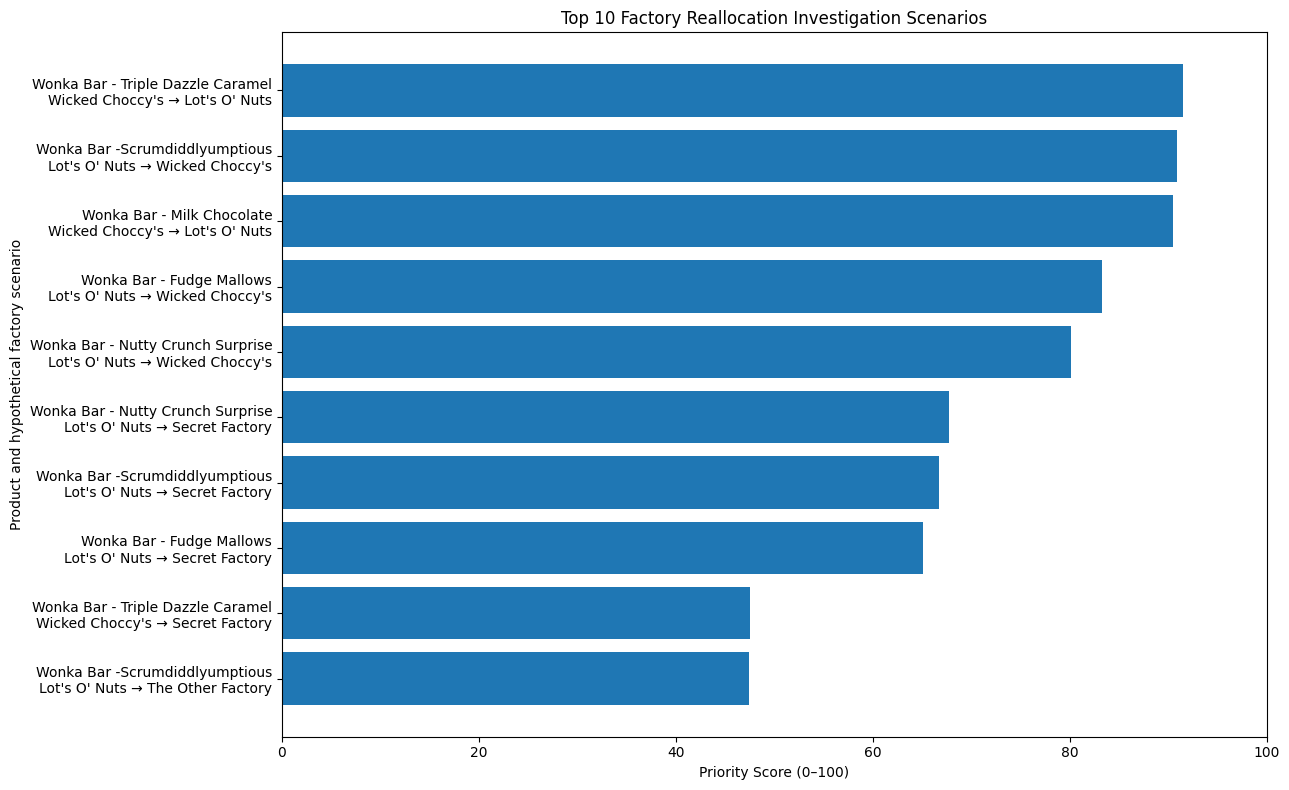

In [54]:

import matplotlib.pyplot as plt
import textwrap

# Select the top 10 scenarios
plot_df = priority_ranking.head(10).copy()

# Create readable labels
plot_df["Scenario"] = plot_df.apply(
    lambda row: (
        f"{row['Product Name']}\n"
        f"{row['Factory']} → {row['Nearest_Factory']}"
    ),
    axis=1
)

# Reverse order so the highest score appears at the top
plot_df = plot_df.sort_values("Priority_Score")

plt.figure(figsize=(13, 8))
plt.barh(
    plot_df["Scenario"],
    plot_df["Priority_Score"]
)

plt.xlabel("Priority Score (0–100)")
plt.ylabel("Product and hypothetical factory scenario")
plt.title("Top 10 Factory Reallocation Investigation Scenarios")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


(0.0, 105.0)

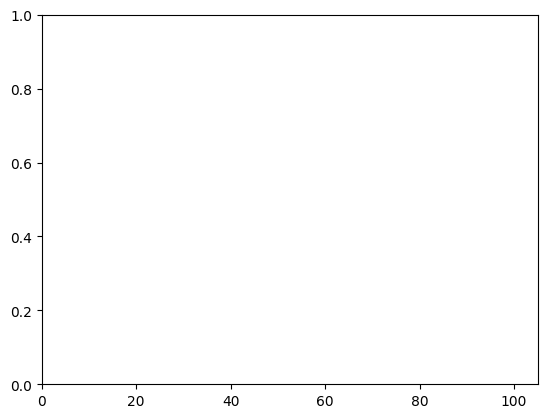

In [55]:
for bar in plt.gca().patches:
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center"
    )

plt.xlim(0, 105)

In [56]:

# Create the final ranked recommendation table
final_recommendations = priority_ranking[
    [
        "Product Name",
        "Factory",
        "Nearest_Factory",
        "Total_Units",
        "Total_Sales",
        "Potential_Distance_Reduction_Percent",
        "Priority_Score"
    ]
].copy()

# Rename columns to make the report more professional
final_recommendations = final_recommendations.rename(
    columns={
        "Product Name": "Product",
        "Factory": "Current_Factory",
        "Nearest_Factory": "Potential_Alternative_Factory",
        "Total_Units": "Units_Affected",
        "Total_Sales": "Associated_Sales",
        "Potential_Distance_Reduction_Percent":
            "Theoretical_Distance_Reduction_Percent"
    }
)

# Add a clear decision status
final_recommendations["Recommendation_Status"] = (
    "Requires factory eligibility, capacity and cost validation"
)

final_recommendations = final_recommendations.reset_index(drop=True)

display(final_recommendations.head(10).round(2))


,Product,Current_Factory,Potential_Alternative_Factory,Units_Affected,Associated_Sales,Theoretical_Distance_Reduction_Percent,Priority_Score,Recommendation_Status
0,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Lot's O' Nuts,2559,9596.25,73.06,91.51,"Requires factory eligibility, capacity and cos..."
1,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Wicked Choccy's,2661,9579.60,71.07,90.86,"Requires factory eligibility, capacity and cos..."
2,Wonka Bar - Milk Chocolate,Wicked Choccy's,Lot's O' Nuts,2677,8700.25,72.84,90.46,"Requires factory eligibility, capacity and cos..."
3,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Wicked Choccy's,2323,8362.80,71.43,83.31,"Requires factory eligibility, capacity and cos..."
4,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Wicked Choccy's,2191,7646.59,71.96,80.09,"Requires factory eligibility, capacity and cos..."
5,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Secret Factory,1311,4575.39,79.91,67.76,"Requires factory eligibility, capacity and cos..."
6,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Secret Factory,1303,4690.80,78.64,66.69,"Requires factory eligibility, capacity and cos..."
7,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Secret Factory,1231,4431.60,78.69,65.06,"Requires factory eligibility, capacity and cos..."
8,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Secret Factory,1381,5178.75,57.18,47.50,"Requires factory eligibility, capacity and cos..."
9,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,The Other Factory,1224,4406.40,61.33,47.45,"Requires factory eligibility, capacity and cos..."


In [57]:

print("FACTORY REALLOCATION ANALYSIS - KEY FINDINGS")
print("-" * 50)

print("Total products analyzed:", df["Product Name"].nunique())
print("Current product-factory assignments:",
      df[["Product Name", "Factory"]].drop_duplicates().shape[0])

print("Scenarios ranked:", len(priority_ranking))

print("\nTop-ranked scenario:")
top_scenario = priority_ranking.iloc[0]

print("Product:", top_scenario["Product Name"])
print("Current factory:", top_scenario["Factory"])
print("Potential alternative:", top_scenario["Nearest_Factory"])
print("Priority score:", round(top_scenario["Priority_Score"], 2))
print("Units affected:", int(top_scenario["Total_Units"]))
print(
    "Theoretical distance reduction (%):",
    round(top_scenario["Potential_Distance_Reduction_Percent"], 2)
)

print("\nNote: These are geographic scenarios, not confirmed transfers.")


FACTORY REALLOCATION ANALYSIS - KEY FINDINGS
--------------------------------------------------
Total products analyzed: 15
Current product-factory assignments: 15
Scenarios ranked: 20

Top-ranked scenario:
Product: Wonka Bar - Triple Dazzle Caramel
Current factory: Wicked Choccy's
Potential alternative: Lot's O' Nuts
Priority score: 91.51
Units affected: 2559
Theoretical distance reduction (%): 73.06

Note: These are geographic scenarios, not confirmed transfers.


In [58]:

# FINAL BUSINESS INSIGHTS

print("=" * 65)
print("FACTORY REALLOCATION & SHIPPING OPTIMIZATION")
print("BUSINESS INSIGHTS AND RECOMMENDATIONS")
print("=" * 65)

print("\n1. PRODUCT COVERAGE")
print(f"Products analyzed: {df['Product Name'].nunique()}")
print(f"Current product-factory assignments: "
      f"{df[['Product Name', 'Factory']].drop_duplicates().shape[0]}")

print("\n2. SCENARIO ANALYSIS")
print(f"Alternative-factory scenarios ranked: {len(priority_ranking)}")
print("Scenarios are ranked using distance reduction, units, and sales.")

print("\n3. HIGHEST-PRIORITY SCENARIO")
top = priority_ranking.iloc[0]

print(f"Product: {top['Product Name']}")
print(f"Current factory: {top['Factory']}")
print(f"Potential alternative: {top['Nearest_Factory']}")
print(f"Units in scenario: {int(top['Total_Units']):,}")
print(f"Associated sales: ${top['Total_Sales']:,.2f}")
print(f"Priority score: {top['Priority_Score']:.2f}/100")
print(
    "Theoretical distance reduction: "
    f"{top['Potential_Distance_Reduction_Percent']:.2f}%"
)

print("\n4. RECOMMENDATIONS")
print("- Validate whether the alternative factory can make the product.")
print("- Check production capacity and operational constraints.")
print("- Obtain actual road distances and transportation costs.")
print("- Investigate shipping-date anomalies before analyzing delivery time.")
print("- Pilot only scenarios that pass operational and financial checks.")

print("\n5. IMPORTANT LIMITATION")
print("The ranking identifies investigation opportunities.")
print("It does not establish actual cost savings or approved transfers.")
print("=" * 65)


FACTORY REALLOCATION & SHIPPING OPTIMIZATION
BUSINESS INSIGHTS AND RECOMMENDATIONS

1. PRODUCT COVERAGE
Products analyzed: 15
Current product-factory assignments: 15

2. SCENARIO ANALYSIS
Alternative-factory scenarios ranked: 20
Scenarios are ranked using distance reduction, units, and sales.

3. HIGHEST-PRIORITY SCENARIO
Product: Wonka Bar - Triple Dazzle Caramel
Current factory: Wicked Choccy's
Potential alternative: Lot's O' Nuts
Units in scenario: 2,559
Associated sales: $9,596.25
Priority score: 91.51/100
Theoretical distance reduction: 73.06%

4. RECOMMENDATIONS
- Validate whether the alternative factory can make the product.
- Check production capacity and operational constraints.
- Obtain actual road distances and transportation costs.
- Investigate shipping-date anomalies before analyzing delivery time.
- Pilot only scenarios that pass operational and financial checks.

5. IMPORTANT LIMITATION
The ranking identifies investigation opportunities.
It does not establish actual cos

In [59]:

# Export the final ranked scenario table
output_file = "factory_reallocation_recommendations.csv"

final_recommendations.to_csv(output_file, index=False)

print("File created:", output_file)
print("Total recommendation scenarios:", len(final_recommendations))

# Download the CSV in Google Colab
from google.colab import files
files.download(output_file)


File created: factory_reallocation_recommendations.csv
Total recommendation scenarios: 20


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:

from datetime import date

# Get the highest-ranked scenario
top = priority_ranking.iloc[0]

report = f"""
FACTORY REALLOCATION & SHIPPING OPTIMIZATION
RECOMMENDATION SYSTEM

Internship Project Report
Organization: Unified Mentor

============================================================
1. ABSTRACT
============================================================

This project analyzes factory assignments and customer destinations
to identify potential geographic opportunities for improving
shipping efficiency. Python and pandas were used for data cleaning,
product-to-factory mapping, geographic distance calculations,
scenario comparison, and prioritization.

The analysis covers {df['Product Name'].nunique()} products and
ranks {len(priority_ranking)} hypothetical alternative-factory
scenarios using distance reduction, unit volume, and sales.

The results provide a shortlist for further investigation. They do
not establish confirmed factory transfers or guaranteed cost savings.

============================================================
2. PROBLEM STATEMENT
============================================================

The project investigates whether the current factory assignments
may result in unnecessarily long distances to customer destinations.
It compares current factory-to-destination distances with distances
to geographically nearer factories.

============================================================
3. PROJECT OBJECTIVES
============================================================

1. Inspect and clean the supplied dataset.
2. Map products to their observed current factories.
3. Geocode customer destinations and factory locations.
4. Calculate geographic distances between factories and destinations.
5. Identify hypothetical alternative-factory scenarios.
6. Rank scenarios for further operational investigation.
7. Present findings and limitations clearly.

============================================================
4. DATASET OVERVIEW
============================================================

Products analyzed: {df['Product Name'].nunique()}
Observed product-factory assignments:
{df[['Product Name', 'Factory']].drop_duplicates().shape[0]}

Total order rows: {len(df):,}

The dataset includes order dates, shipping dates, products,
factories inferred from the project mapping, sales, units,
gross profit, costs, and customer destination information.

============================================================
5. METHODOLOGY
============================================================

Step 1: Data inspection and quality checks.
Step 2: Product-to-factory mapping.
Step 3: Geocoding of customer destinations.
Step 4: Geographic distance calculations using the Haversine method.
Step 5: Comparison of current and nearest factory distances.
Step 6: Scenario ranking using distance reduction, unit volume,
        and sales.
Step 7: Visualization and business interpretation.

The calculated distances represent straight-line geographic
distances, not verified road or shipping-route distances.

============================================================
6. KEY FINDINGS
============================================================

Number of products analyzed: {df['Product Name'].nunique()}
Number of scenarios ranked: {len(priority_ranking)}

Highest-ranked scenario:
Product: {top['Product Name']}
Current factory: {top['Factory']}
Potential alternative: {top['Nearest_Factory']}
Units in scenario: {int(top['Total_Units']):,}
Associated sales: ${top['Total_Sales']:,.2f}
Priority score: {top['Priority_Score']:.2f}/100
Theoretical distance reduction:
{top['Potential_Distance_Reduction_Percent']:.2f}%

This scenario is the highest-ranked candidate under the selected
scoring method. It is not yet a confirmed production transfer.

============================================================
7. RECOMMENDATIONS
============================================================

1. Verify whether each alternative factory can manufacture the
   relevant product.
2. Validate production capacity and operational constraints.
3. Obtain road-route distances and actual transportation rates.
4. Verify suspicious shipping dates before drawing conclusions
   about delivery lead times.
5. Compare operational and financial feasibility before any pilot.

============================================================
8. LIMITATIONS
============================================================

- Alternative factory product eligibility is unverified.
- Factory production capacity is not available in the analysis.
- Straight-line distance is only a geographic approximation.
- Actual shipping costs and delivery times have not been calculated.
- The priority score depends on the chosen scoring weights.
- Shipping-date anomalies require source-data verification.

============================================================
9. FUTURE SCOPE
============================================================

Future work can incorporate factory capacity, product compatibility,
road-network distances, transportation rates, delivery service
levels, and production costs. An optimization model could then
select feasible assignments while minimizing total cost or distance.

============================================================
10. CONCLUSION
============================================================

The project establishes a data-driven process for identifying and
ranking potential factory-to-destination improvements. The results
provide a foundation for further operational validation and
transportation-cost analysis. Final factory decisions require
additional verified production and logistics data.

============================================================
Report generated: {date.today().isoformat()}
============================================================
"""

with open("Factory_Reallocation_Project_Report.txt", "w",
          encoding="utf-8") as file:
    file.write(report)

print("Project report created successfully!")
print(report)


Project report created successfully!

FACTORY REALLOCATION & SHIPPING OPTIMIZATION
RECOMMENDATION SYSTEM

Internship Project Report
Organization: Unified Mentor

1. ABSTRACT

This project analyzes factory assignments and customer destinations
to identify potential geographic opportunities for improving
shipping efficiency. Python and pandas were used for data cleaning,
product-to-factory mapping, geographic distance calculations,
scenario comparison, and prioritization.

The analysis covers 15 products and
ranks 20 hypothetical alternative-factory
scenarios using distance reduction, unit volume, and sales.

The results provide a shortlist for further investigation. They do
not establish confirmed factory transfers or guaranteed cost savings.

2. PROBLEM STATEMENT

The project investigates whether the current factory assignments
may result in unnecessarily long distances to customer destinations.
It compares current factory-to-destination distances with distances
to geographically neare

In [61]:

from google.colab import files

files.download("Factory_Reallocation_Project_Report.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:

import pandas as pd

# Display all DataFrames already created in this notebook
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataFrame: {name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())



DataFrame: df
Shape: (10194, 23)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead Time Days', 'Factory', 'Factory Latitude', 'Factory Longitude', 'Date Quality Flag']

DataFrame: region_summary
Shape: (4, 4)
Columns: ['Total_Sales', 'Total_Profit', 'Total_Units', 'Order_Count']

DataFrame: shipping_summary
Shape: (4, 4)
Columns: ['Orders', 'Sales', 'Gross_Profit', 'Units']

DataFrame: factory_locations
Shape: (5, 3)
Columns: ['Factory', 'Factory Latitude', 'Factory Longitude']

DataFrame: factory_df
Shape: (5, 3)
Columns: ['Factory', 'Latitude', 'Longitude']

DataFrame: mode_summary
Shape: (4, 5)
Columns: ['Orders', 'Minimum', 'Median', 'Average', 'Maximum']

DataFrame: group
Shape: (6120, 22)
Columns: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Reg

In [63]:

# Check the destination coordinates before applying ML

print("Total destinations:", len(destinations_geo))

print("\nMissing latitude values:",
      destinations_geo["Latitude"].isna().sum())

print("Missing longitude values:",
      destinations_geo["Longitude"].isna().sum())

print("\nGeocoding methods:")
print(destinations_geo["Geocode_Method"].value_counts(dropna=False))

print("\nSample destination coordinates:")
display(
    destinations_geo[
        ["City", "State/Province", "Latitude",
         "Longitude", "Geocode_Method", "Total_Units"]
    ].head(10)
)


Total destinations: 655

Missing latitude values: 0
Missing longitude values: 0

Geocoding methods:
Geocode_Method
Full address          632
City/state/country     23
Name: count, dtype: int64

Sample destination coordinates:


,City,State/Province,Latitude,Longitude,Geocode_Method,Total_Units
0,Calgary,Alberta,51.045606,-114.057541,City/state/country,15
1,Calgary,Alberta,50.982956,-113.973914,Full address,69
2,Charlottetown,Prince Edward Island,46.235419,-63.126539,City/state/country,38
3,Edmonton,Alberta,53.546205,-113.491241,City/state/country,26
4,Halifax,Nova Scotia,44.648618,-63.585949,City/state/country,26
5,Moncton,New Brunswick,46.083949,-64.786053,Full address,48
6,Montreal,Quebec,45.503182,-73.569806,City/state/country,75
7,Montreal,Quebec,45.503182,-73.569806,City/state/country,8
8,Montreal,Quebec,45.503182,-73.569806,City/state/country,18
9,Quebec City,Quebec,46.813743,-71.208406,City/state/country,49


In [64]:

# STEP 2A: Validate destination data

import pandas as pd
import numpy as np

geo = destinations_geo.copy()

# Convert coordinates to numeric values
geo["Latitude"] = pd.to_numeric(geo["Latitude"], errors="coerce")
geo["Longitude"] = pd.to_numeric(geo["Longitude"], errors="coerce")

# Check invalid or missing coordinates
invalid = (
    geo["Latitude"].isna()
    | geo["Longitude"].isna()
    | ~geo["Latitude"].between(-90, 90)
    | ~geo["Longitude"].between(-180, 180)
)

print("Invalid coordinates:", invalid.sum())
print("Duplicate coordinate pairs:",
      geo.duplicated(["Latitude", "Longitude"]).sum())

print("\nCountries represented:")
print(geo["Country/Region"].value_counts(dropna=False))

print("\nCoordinate ranges:")
print(geo[["Latitude", "Longitude"]].describe())

print("\nUnique coordinate pairs:",
      geo[["Latitude", "Longitude"]].drop_duplicates().shape[0])


Invalid coordinates: 0
Duplicate coordinate pairs: 38

Countries represented:
Country/Region
United States    632
Canada            23
Name: count, dtype: int64

Coordinate ranges:
         Latitude   Longitude
count  655.000000  655.000000
mean    38.047933  -93.981912
std      5.427457   16.414638
min     25.471895 -123.113952
25%     33.957984 -109.385185
50%     38.974250  -89.290339
75%     41.906002  -80.919956
max     53.546205  -52.706696

Unique coordinate pairs: 617


Clustering evaluation:


,Number_of_Clusters,Silhouette_Score
0,2,0.5818
1,3,0.4440
2,4,0.4655
3,5,0.5008
4,6,0.5020
5,7,0.5230
6,8,0.5113
7,9,0.5147
8,10,0.5075


Best exploratory cluster count: 2

Number of destination records: 655
Number of unique geographic clusters: 2

Destinations in each cluster:


,Destination_Count
Cluster,
0,458
1,197


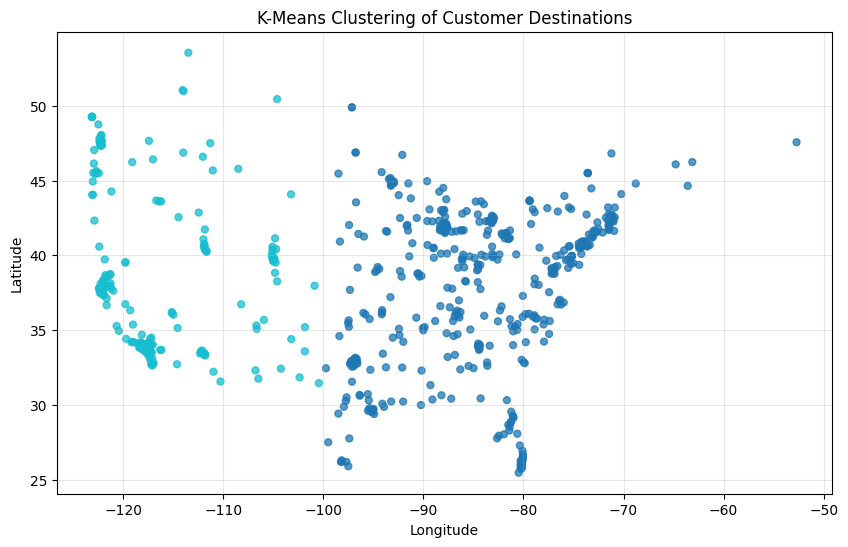

In [65]:

# STEP 3A: Apply K-Means clustering to destination locations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Copy the required columns
geo = destinations_geo[
    ["Latitude", "Longitude"]
].copy()

geo["Latitude"] = pd.to_numeric(geo["Latitude"], errors="coerce")
geo["Longitude"] = pd.to_numeric(geo["Longitude"], errors="coerce")
geo = geo.dropna().copy()

# 2. Use unique locations to avoid duplicate coordinates
unique_locations = geo.drop_duplicates(
    subset=["Latitude", "Longitude"]
).copy()

# 3. Convert latitude and longitude to radians
# This represents locations on a sphere and handles longitude
# more appropriately than clustering raw latitude/longitude.
lat_rad = np.radians(unique_locations["Latitude"].to_numpy())
lon_rad = np.radians(unique_locations["Longitude"].to_numpy())

# 4. Convert each location into 3D spherical coordinates
X = np.column_stack([
    np.cos(lat_rad) * np.cos(lon_rad),
    np.cos(lat_rad) * np.sin(lon_rad),
    np.sin(lat_rad)
])

# 5. Test cluster counts from 2 to 10
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    results.append({
        "Number_of_Clusters": k,
        "Silhouette_Score": score
    })

scores_df = pd.DataFrame(results)

print("Clustering evaluation:")
display(scores_df.round(4))

# 6. Select the cluster count with the highest silhouette score
best_k = int(
    scores_df.loc[
        scores_df["Silhouette_Score"].idxmax(),
        "Number_of_Clusters"
    ]
)

print("Best exploratory cluster count:", best_k)

# 7. Train the final K-Means model
kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

unique_locations["Cluster"] = kmeans_model.fit_predict(X)

# 8. Assign the cluster labels back to all destination records
geo = geo.merge(
    unique_locations,
    on=["Latitude", "Longitude"],
    how="left"
)

destinations_clustered = destinations_geo.copy()
destinations_clustered["Cluster"] = geo["Cluster"].to_numpy()

print("\nNumber of destination records:",
      len(destinations_clustered))

print("Number of unique geographic clusters:",
      destinations_clustered["Cluster"].nunique())

print("\nDestinations in each cluster:")
display(
    destinations_clustered["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Destination_Count")
    .to_frame()
)

# 9. Visualize the geographic clusters
plt.figure(figsize=(10, 6))

plt.scatter(
    destinations_clustered["Longitude"],
    destinations_clustered["Latitude"],
    c=destinations_clustered["Cluster"],
    cmap="tab10",
    s=25,
    alpha=0.75
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("K-Means Clustering of Customer Destinations")
plt.grid(True, alpha=0.3)
plt.show()


Geographic Cluster Summary:


,Cluster,Destination_Records,Unique_Cities,Total_Units,Average_Latitude,Average_Longitude
0,0,458,386,26022,37.78,-84.47
1,1,197,179,12632,38.68,-116.09



Cluster demand shares:


,Cluster,Total_Units,Demand_Share_Percent
0,0,26022,67.32
1,1,12632,32.68


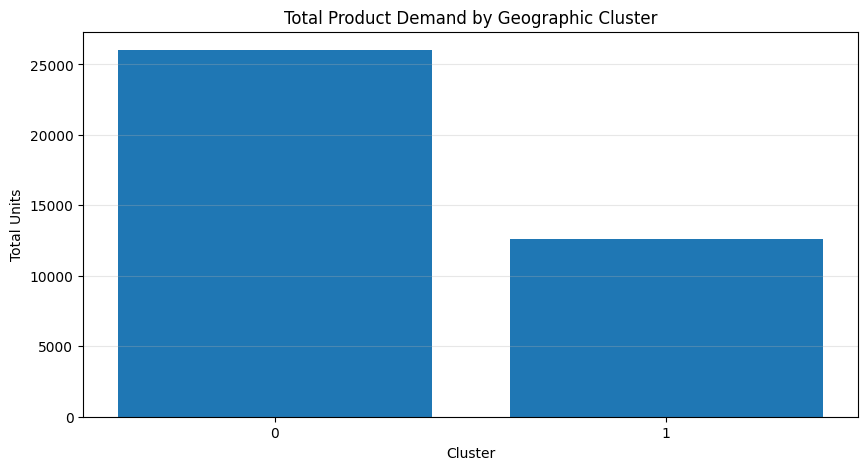

In [66]:

# STEP 4: Analyze the clusters

import pandas as pd
import matplotlib.pyplot as plt

# 1. Summarize each cluster
cluster_summary = (
    destinations_clustered
    .groupby("Cluster")
    .agg(
        Destination_Records=("City", "size"),
        Unique_Cities=("City", "nunique"),
        Total_Units=("Total_Units", "sum"),
        Average_Latitude=("Latitude", "mean"),
        Average_Longitude=("Longitude", "mean")
    )
    .reset_index()
)

print("Geographic Cluster Summary:")
display(cluster_summary.round(2))

# 2. Calculate each cluster's share of total demand
total_units = cluster_summary["Total_Units"].sum()

cluster_summary["Demand_Share_Percent"] = (
    cluster_summary["Total_Units"] / total_units * 100
)

print("\nCluster demand shares:")
display(
    cluster_summary[
        ["Cluster", "Total_Units", "Demand_Share_Percent"]
    ].round(2)
)

# 3. Visualize the demand in each cluster
plt.figure(figsize=(10, 5))

plt.bar(
    cluster_summary["Cluster"].astype(str),
    cluster_summary["Total_Units"]
)

plt.xlabel("Cluster")
plt.ylabel("Total Units")
plt.title("Total Product Demand by Geographic Cluster")
plt.grid(axis="y", alpha=0.3)
plt.show()


In [67]:

# STEP 5: Calculate distances from destinations to factories

import numpy as np
import pandas as pd

# Factory locations from the project
factories = pd.DataFrame([
    {
        "Factory": "Lot's O' Nuts",
        "Factory_Latitude": 32.881893,
        "Factory_Longitude": -111.768036
    },
    {
        "Factory": "Wicked Choccy's",
        "Factory_Latitude": 32.076176,
        "Factory_Longitude": -81.088371
    },
    {
        "Factory": "Sugar Shack",
        "Factory_Latitude": 48.119140,
        "Factory_Longitude": -96.181150
    },
    {
        "Factory": "Secret Factory",
        "Factory_Latitude": 41.446333,
        "Factory_Longitude": -90.565487
    },
    {
        "Factory": "The Other Factory",
        "Factory_Latitude": 35.117500,
        "Factory_Longitude": -89.971107
    }
])

# Haversine formula: approximate distance over Earth's surface
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = np.clip(a, 0, 1)

    return 6371 * 2 * np.arcsin(np.sqrt(a))


# Keep one row per destination record
destination_factory_results = destinations_clustered.copy()

nearest_factories = []
nearest_distances = []

for _, destination in destination_factory_results.iterrows():

    distances = []

    for _, factory in factories.iterrows():
        distance = haversine_km(
            destination["Latitude"],
            destination["Longitude"],
            factory["Factory_Latitude"],
            factory["Factory_Longitude"]
        )

        distances.append(distance)

    nearest_index = int(np.argmin(distances))

    nearest_factories.append(
        factories.iloc[nearest_index]["Factory"]
    )
    nearest_distances.append(distances[nearest_index])

destination_factory_results["Nearest_Factory"] = nearest_factories
destination_factory_results["Nearest_Factory_Distance_km"] = (
    nearest_distances
)

print("Sample destination-to-factory results:")
display(
    destination_factory_results[
        [
            "City",
            "State/Province",
            "Cluster",
            "Nearest_Factory",
            "Nearest_Factory_Distance_km"
        ]
    ].head(10).round(2)
)

print("\nDestinations assigned to each nearest factory:")
display(
    destination_factory_results
    .groupby("Nearest_Factory")
    .agg(
        Destination_Records=("City", "size"),
        Total_Units=("Total_Units", "sum")
    )
    .reset_index()
)


Sample destination-to-factory results:


,City,State/Province,Cluster,Nearest_Factory,Nearest_Factory_Distance_km
0,Calgary,Alberta,1,Sugar Shack,1325.58
1,Calgary,Alberta,1,Sugar Shack,1318.91
2,Charlottetown,Prince Edward Island,0,Wicked Choccy's,2198.40
3,Edmonton,Alberta,1,Sugar Shack,1352.47
4,Halifax,Nova Scotia,0,Wicked Choccy's,2061.33
5,Moncton,New Brunswick,0,Wicked Choccy's,2090.79
6,Montreal,Quebec,0,Secret Factory,1440.42
7,Montreal,Quebec,0,Secret Factory,1440.42
8,Montreal,Quebec,0,Secret Factory,1440.42
9,Quebec City,Quebec,0,Secret Factory,1650.83



Destinations assigned to each nearest factory:


,Nearest_Factory,Destination_Records,Total_Units
0,Lot's O' Nuts,177,12287
1,Secret Factory,158,6970
2,Sugar Shack,31,622
3,The Other Factory,109,5884
4,Wicked Choccy's,180,12891


In [68]:

# STEP 6A: Find the current factory column

print("Available columns:")
print(destinations_clustered.columns.tolist())

print("\nPossible current factory columns:")

for col in destinations_clustered.columns:
    if "factory" in col.lower():
        print("-", col)


Available columns:
['Country/Region', 'City', 'State/Province', 'Postal Code', 'Total_Units', 'Total_Sales', 'Total_Orders', 'Full_Address', 'Latitude', 'Longitude', 'Geocode_Method', 'Destination_ID', 'Cluster']

Possible current factory columns:


In [69]:

# Check which columns are available in the original dataset

print("Original dataset columns:")
print(df.columns.tolist())

print("\nFactory-related columns:")

for col in df.columns:
    if "factory" in col.lower():
        print("-", col)

print("\nSample factory assignments:")

if "Factory" in df.columns:
    display(df[["City", "State/Province", "Factory"]].head(10))
else:
    print("No column named 'Factory' found.")


Original dataset columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead Time Days', 'Factory', 'Factory Latitude', 'Factory Longitude', 'Date Quality Flag']

Factory-related columns:
- Factory
- Factory Latitude
- Factory Longitude

Sample factory assignments:


,City,State/Province,Factory
0,Houston,Texas,Wicked Choccy's
1,Naperville,Illinois,Wicked Choccy's
2,Naperville,Illinois,Lot's O' Nuts
3,Naperville,Illinois,Lot's O' Nuts
4,Philadelphia,Pennsylvania,Wicked Choccy's
5,Henderson,Kentucky,Lot's O' Nuts
6,Henderson,Kentucky,Wicked Choccy's
7,Athens,Georgia,Wicked Choccy's
8,Henderson,Kentucky,Lot's O' Nuts
9,Henderson,Kentucky,Wicked Choccy's


In [70]:

import pandas as pd
import numpy as np

# 1. Prepare the order-level data
orders = df.copy()

# Standardize postal codes as text for matching
def clean_text(series):
    return series.fillna("").astype(str).str.strip().str.casefold()

orders["Country_Key"] = clean_text(orders["Country/Region"])
orders["City_Key"] = clean_text(orders["City"])
orders["State_Key"] = clean_text(orders["State/Province"])
orders["Postal_Key"] = clean_text(orders["Postal Code"])

# 2. Prepare destination coordinates
dest = destinations_geo.copy()

dest["Country_Key"] = clean_text(dest["Country/Region"])
dest["City_Key"] = clean_text(dest["City"])
dest["State_Key"] = clean_text(dest["State/Province"])
dest["Postal_Key"] = clean_text(dest["Postal Code"])

# 3. Match by full available geographic details
# First try country + city + state + postal code.
# If a postal code is missing on either side, use country + city + state.
dest_exact = dest[
    [
        "Country_Key", "City_Key", "State_Key", "Postal_Key",
        "Latitude", "Longitude"
    ]
].drop_duplicates()

dest_city = dest[
    [
        "Country_Key", "City_Key", "State_Key",
        "Latitude", "Longitude"
    ]
].drop_duplicates()

orders["Latitude"] = np.nan
orders["Longitude"] = np.nan

# Match exact postal codes when both sides have one
has_postal = orders["Postal_Key"].ne("")

exact_matches = orders.loc[has_postal].merge(
    dest_exact,
    on=["Country_Key", "City_Key", "State_Key", "Postal_Key"],
    how="left",
    suffixes=("", "_dest")
)

orders.loc[has_postal, "Latitude"] = exact_matches["Latitude"].to_numpy()
orders.loc[has_postal, "Longitude"] = exact_matches["Longitude"].to_numpy()

# For unmatched rows, use city/state/country only when that combination
# maps to exactly one distinct coordinate pair.
for idx in orders.index[orders["Latitude"].isna()]:
    row = orders.loc[idx]

    candidates = dest_city[
        (dest_city["Country_Key"] == row["Country_Key"])
        & (dest_city["City_Key"] == row["City_Key"])
        & (dest_city["State_Key"] == row["State_Key"])
    ]

    candidates = candidates[
        ["Latitude", "Longitude"]
    ].drop_duplicates()

    if len(candidates) == 1:
        orders.loc[idx, "Latitude"] = candidates.iloc[0]["Latitude"]
        orders.loc[idx, "Longitude"] = candidates.iloc[0]["Longitude"]

print("Orders:", len(orders))
print("Orders matched to coordinates:", orders["Latitude"].notna().sum())
print("Orders without coordinates:", orders["Latitude"].isna().sum())


Orders: 10194
Orders matched to coordinates: 10176
Orders without coordinates: 18


In [71]:

# STEP 8: Compare current factory distances with nearest-factory distances

import numpy as np
import pandas as pd

# Haversine formula: straight-line distance in kilometres
def haversine_km(lat1, lon1, lat2, lon2):
    # Convert each coordinate to radians individually to handle mixed scalar/array inputs safely
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    a = np.clip(a, 0, 1)

    return 6371 * 2 * np.arcsin(np.sqrt(a))


# Keep orders that have valid destination coordinates
matched_orders = orders.dropna(
    subset=["Latitude", "Longitude"]
).copy()

# Map each currently assigned factory to its coordinates
factory_coords = factories.set_index("Factory")

matched_orders["Current_Factory_Latitude"] = (
    matched_orders["Factory"].map(
        factory_coords["Factory_Latitude"]
    )
)

matched_orders["Current_Factory_Longitude"] = (
    matched_orders["Factory"].map(
        factory_coords["Factory_Longitude"]
    )
)

# Check whether every current factory has a coordinate mapping
missing_factory_coords = matched_orders[
    [
        "Current_Factory_Latitude",
        "Current_Factory_Longitude"
    ]
].isna().any(axis=1)

print("Orders with unknown current factory coordinates:",
      missing_factory_coords.sum())

# Only calculate distances where both factory and destination
# coordinates are available
matched_orders = matched_orders.loc[
    ~missing_factory_coords
].copy()

# Calculate distance from the currently assigned factory
matched_orders["Current_Distance_km"] = haversine_km(
    matched_orders["Current_Factory_Latitude"],
    matched_orders["Current_Factory_Longitude"],
    matched_orders["Latitude"],
    matched_orders["Longitude"]
)

# Calculate distance to every factory and identify the nearest one
all_factory_distances = []

for _, factory in factories.iterrows():
    distance = haversine_km(
        matched_orders["Latitude"].to_numpy(),
        matched_orders["Longitude"].to_numpy(),
        factory["Factory_Latitude"],
        factory["Factory_Longitude"]
    )

    all_factory_distances.append(distance)

distance_matrix = np.column_stack(all_factory_distances)

nearest_indices = distance_matrix.argmin(axis=1)

matched_orders["Nearest_Factory"] = (
    factories.iloc[nearest_indices]["Factory"].to_numpy()
)

matched_orders["Nearest_Distance_km"] = (
    distance_matrix.min(axis=1)
)

# Estimate potential distance reduction
matched_orders["Potential_Saving_km"] = (
    matched_orders["Current_Distance_km"]
    - matched_orders["Nearest_Distance_km"]
).clip(lower=0)

matched_orders["Potential_Saving_Percent"] = np.where(
    matched_orders["Current_Distance_km"] > 0,
    matched_orders["Potential_Saving_km"]
    / matched_orders["Current_Distance_km"] * 100,
    0
)

print("\nDistance comparison sample:")
display(
    matched_orders[
        [
            "Order ID",
            "Factory",
            "Nearest_Factory",
            "Current_Distance_km",
            "Nearest_Distance_km",
            "Potential_Saving_km",
            "Potential_Saving_Percent"
        ]
    ].head(10).round(2)
)

print("\nOverall distance summary:")
print("Orders compared:", len(matched_orders))
print(
    "Average current distance (km):",
    round(matched_orders["Current_Distance_km"].mean(), 2)
)
print(
    "Average nearest-factory distance (km):",
    round(matched_orders["Nearest_Distance_km"].mean(), 2)
)
print(
    "Average potential saving per order (km):",
    round(matched_orders["Potential_Saving_km"].mean(), 2)
)
print(
    "Orders with a different nearest factory:",
    (
        matched_orders["Factory"]
        != matched_orders["Nearest_Factory"]
    ).sum()
)


Orders with unknown current factory coordinates: 0

Distance comparison sample:


,Order ID,Factory,Nearest_Factory,Current_Distance_km,Nearest_Distance_km,Potential_Saving_km,Potential_Saving_Percent
0,US-2021-103800-CHO-MIL-31000,Wicked Choccy's,The Other Factory,1385.22,781.70,603.53,43.57
1,US-2021-112326-CHO-TRI-54000,Wicked Choccy's,Secret Factory,1246.46,204.24,1042.22,83.61
2,US-2021-112326-CHO-NUT-13000,Lot's O' Nuts,Secret Factory,2300.48,204.24,2096.25,91.12
3,US-2021-112326-CHO-SCR-58000,Lot's O' Nuts,Secret Factory,2300.48,204.24,2096.25,91.12
4,US-2021-141817-CHO-TRI-54000,Wicked Choccy's,Wicked Choccy's,1024.60,1024.60,0.00,0.00
5,US-2021-167199-CHO-SCR-58000,Lot's O' Nuts,The Other Factory,2253.62,370.04,1883.57,83.58
6,US-2021-167199-CHO-TRI-54000,Wicked Choccy's,The Other Factory,872.50,370.04,502.46,57.59
7,US-2021-106054-CHO-MIL-31000,Wicked Choccy's,Wicked Choccy's,298.94,298.94,0.00,0.00
8,US-2021-167199-CHO-NUT-13000,Lot's O' Nuts,The Other Factory,2253.62,370.04,1883.57,83.58
9,US-2021-167199-CHO-MIL-31000,Wicked Choccy's,The Other Factory,872.50,370.04,502.46,57.59



Overall distance summary:
Orders compared: 10176
Average current distance (km): 2006.98
Average nearest-factory distance (km): 816.05
Average potential saving per order (km): 1190.94
Orders with a different nearest factory: 6949


In [72]:

# STEP 10: Factory-wise analysis and export

# 1. Summarize current factory assignments
factory_summary = (
    matched_orders.groupby("Factory")
    .agg(
        Order_Lines=("Order ID", "size"),
        Total_Units=("Units", "sum"),
        Current_Avg_Distance_km=("Current_Distance_km", "mean"),
        Nearest_Avg_Distance_km=("Nearest_Distance_km", "mean"),
        Avg_Potential_Saving_km=("Potential_Saving_km", "mean"),
        Lines_Eligible_for_Reassignment=(
            "Potential_Saving_km",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
)

factory_summary["Potential_Reduction_Percent"] = (
    (
        factory_summary["Current_Avg_Distance_km"]
        - factory_summary["Nearest_Avg_Distance_km"]
    )
    / factory_summary["Current_Avg_Distance_km"]
    * 100
)

print("Results grouped by CURRENT factory:")
display(factory_summary.round(2))

# 2. Summarize nearest-factory assignments
nearest_summary = (
    matched_orders.groupby("Nearest_Factory")
    .agg(
        Assigned_Order_Lines=("Order ID", "size"),
        Total_Units=("Units", "sum"),
        Average_Distance_km=("Nearest_Distance_km", "mean")
    )
    .reset_index()
)

print("\nHypothetical nearest-factory distribution:")
display(nearest_summary.round(2))

# 3. Export the detailed analysis and summaries
matched_orders.to_csv(
    "factory_distance_comparison.csv",
    index=False
)

factory_summary.to_csv(
    "factory_wise_distance_summary.csv",
    index=False
)

nearest_summary.to_csv(
    "nearest_factory_distribution.csv",
    index=False
)

print("\nFiles saved:")
print("1. factory_distance_comparison.csv")
print("2. factory_wise_distance_summary.csv")
print("3. nearest_factory_distribution.csv")


Results grouped by CURRENT factory:


,Factory,Order_Lines,Total_Units,Current_Avg_Distance_km,Nearest_Avg_Distance_km,Avg_Potential_Saving_km,Lines_Eligible_for_Reassignment,Potential_Reduction_Percent
0,Lot's O' Nuts,5682,21375,2144.38,818.72,1325.67,3893,61.82
1,Secret Factory,215,875,1430.06,804.23,625.83,168,43.76
2,Sugar Shack,33,107,1797.05,853.13,943.93,33,52.53
3,The Other Factory,100,388,1642.32,902.70,739.63,84,45.04
4,Wicked Choccy's,4146,15825,1859.07,810.61,1048.46,2771,56.40



Hypothetical nearest-factory distribution:


,Nearest_Factory,Assigned_Order_Lines,Total_Units,Average_Distance_km
0,Lot's O' Nuts,3217,12287,937.09
1,Secret Factory,1853,6970,535.33
2,Sugar Shack,140,538,858.10
3,The Other Factory,1536,5884,638.13
4,Wicked Choccy's,3430,12891,932.13



Files saved:
1. factory_distance_comparison.csv
2. factory_wise_distance_summary.csv
3. nearest_factory_distribution.csv


In [73]:

# STEP 11: Validate totals and factory assignments

print("Matched rows:", len(matched_orders))

print("\nTotal units in matched data:")
print(matched_orders["Units"].sum())

print("\nTotal units by current factory:")
display(
    matched_orders.groupby("Factory")["Units"]
    .sum()
    .rename("Units")
    .reset_index()
)

print("\nTotal units by nearest factory:")
display(
    matched_orders.groupby("Nearest_Factory")["Units"]
    .sum()
    .rename("Units")
    .reset_index()
)

print("\nMissing unit values:",
      matched_orders["Units"].isna().sum())

print("\nNegative unit values:",
      (matched_orders["Units"] < 0).sum())

print("\nMissing current factory values:",
      matched_orders["Factory"].isna().sum())

print("\nCurrent factory names:")
print(sorted(matched_orders["Factory"].dropna().unique()))

print("\nNearest factory names:")
print(sorted(matched_orders["Nearest_Factory"].dropna().unique()))


Matched rows: 10176

Total units in matched data:
38570

Total units by current factory:


,Factory,Units
0,Lot's O' Nuts,21375
1,Secret Factory,875
2,Sugar Shack,107
3,The Other Factory,388
4,Wicked Choccy's,15825



Total units by nearest factory:


,Nearest_Factory,Units
0,Lot's O' Nuts,12287
1,Secret Factory,6970
2,Sugar Shack,538
3,The Other Factory,5884
4,Wicked Choccy's,12891



Missing unit values: 0

Negative unit values: 0

Missing current factory values: 0

Current factory names:
["Lot's O' Nuts", 'Secret Factory', 'Sugar Shack', 'The Other Factory', "Wicked Choccy's"]

Nearest factory names:
["Lot's O' Nuts", 'Secret Factory', 'Sugar Shack', 'The Other Factory', "Wicked Choccy's"]


Selected number of clusters: 2
Silhouette score: 0.5818

Unique locations in each cluster:


,Cluster,Unique_Locations
0,0,435
1,1,182


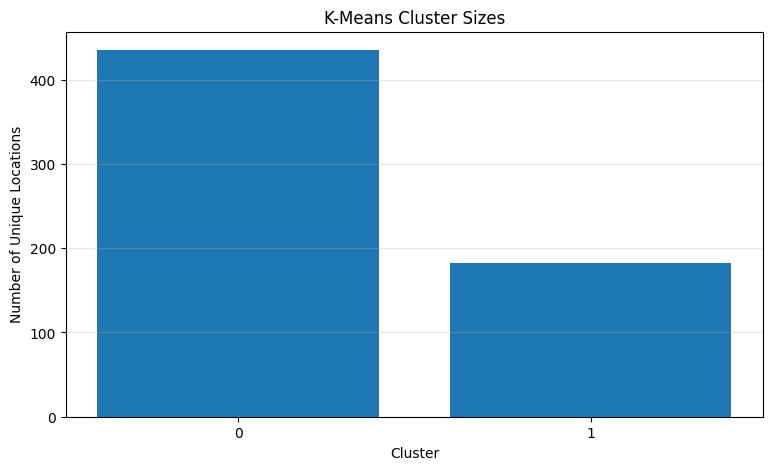


Saved: destinations_with_clusters.csv


In [74]:

# STEP 12: Evaluate the K-Means clustering model

from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

# 1. Calculate the silhouette score for the selected model
X_eval = X
labels = unique_locations["Cluster"].to_numpy()

score = silhouette_score(X_eval, labels)

print("Selected number of clusters:", best_k)
print("Silhouette score:", round(score, 4))

# 2. Summarize cluster sizes
cluster_sizes = (
    unique_locations.groupby("Cluster")
    .size()
    .reset_index(name="Unique_Locations")
)

print("\nUnique locations in each cluster:")
display(cluster_sizes)

# 3. Plot cluster sizes
plt.figure(figsize=(9, 5))

plt.bar(
    cluster_sizes["Cluster"].astype(str),
    cluster_sizes["Unique_Locations"]
)

plt.xlabel("Cluster")
plt.ylabel("Number of Unique Locations")
plt.title("K-Means Cluster Sizes")
plt.grid(axis="y", alpha=0.3)
plt.show()

# 4. Save the clustered destinations
destinations_clustered.to_csv(
    "destinations_with_clusters.csv",
    index=False
)

print("\nSaved: destinations_with_clusters.csv")


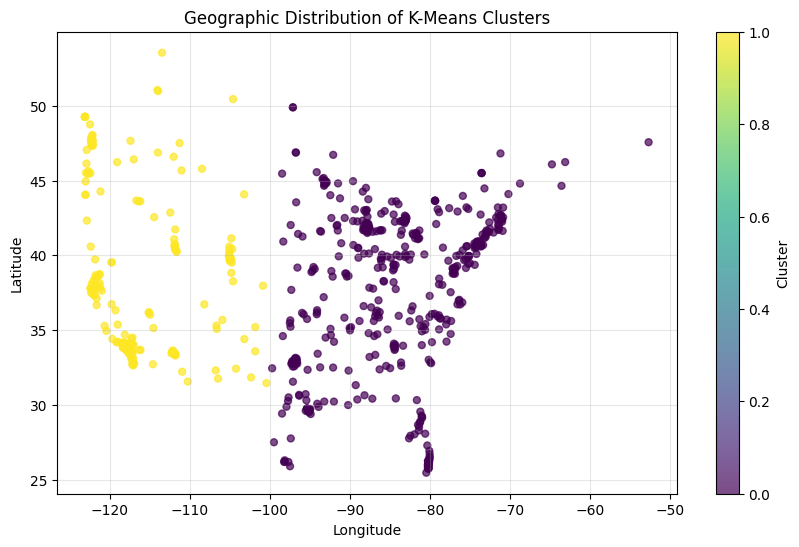

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    destinations_clustered["Longitude"],
    destinations_clustered["Latitude"],
    c=destinations_clustered["Cluster"],
    cmap="viridis",
    s=25,
    alpha=0.7
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographic Distribution of K-Means Clusters")
plt.colorbar(label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

In [76]:
import joblib

# Save the trained K-Means model
joblib.dump(kmeans_model, "kmeans_factory_clusters.pkl")

# Save destination data with cluster labels
destinations_clustered.to_csv(
    "destinations_with_clusters.csv",
    index=False
)

# Save silhouette scores for your report
scores_df.to_csv("kmeans_silhouette_scores.csv", index=False)

print("K-Means model and results saved successfully!")

K-Means model and results saved successfully!
